In [7]:
import pandas as pd

df = pd.read_excel("Project_1_Banking_Data.xlsx")

print(df)

              Bank    Year  Deposits  Advances  Total_Assets  Net_Profit  \
0              SBI  FY2021   3681277   2449498       4534430       20410   
1              SBI  FY2022   4051534   2733967       4987597       31676   
2              SBI  FY2023   4423778   3199269       5516979       50232   
3              SBI  FY2024   4916077   3703971       6179694       61077   
4              SBI  FY2025   5382190   4163312       6676053       70901   
5       ICICI Bank  FY2021    932522    733729       1230433       16193   
6       ICICI Bank  FY2022   1064572    859020       1411298       23339   
7       ICICI Bank  FY2023   1180841   1019674       1584207       31896   
8       ICICI Bank  FY2024   1412825   1184406       1871586       40888   
9       ICICI Bank  FY2025   1610348   1340000       2120000       54449   
10       HDFC Bank  FY2021   1335060   1132837       1746871       31117   
11       HDFC Bank  FY2022   1559217   1368821       2068535       36961   
12       HDF

In [8]:
print(df.head())

print(df.tail())

print(df.shape)

print(df.columns)

print(df.info())

print(df.describe())

print(df.isnull().sum())

print(df.duplicated().sum())

  Bank    Year  Deposits  Advances  Total_Assets  Net_Profit     ROA     ROE  \
0  SBI  FY2021   3681277   2449498       4534430       20410  0.0048  0.0994   
1  SBI  FY2022   4051534   2733967       4987597       31676  0.0067  0.1392   
2  SBI  FY2023   4423778   3199269       5516979       50232  0.0096  0.1943   
3  SBI  FY2024   4916077   3703971       6179694       61077  0.0104  0.2032   
4  SBI  FY2025   5382190   4163312       6676053       70901  0.0110  0.1987   

     GNPA    NNPA     CAR     NIM  Provision Coverage Ratio  Cost/Income Ratio  
0  0.0498  0.0150  0.1374  0.0304                    0.7088             0.5360  
1  0.0397  0.0102  0.1383  0.0312                    0.7504             0.5331  
2  0.0278  0.0067  0.1468  0.0337                    0.7639             0.5387  
3  0.0224  0.0057  0.1428  0.0328                    0.7502             0.5566  
4  0.0182  0.0047  0.1425  0.0309                    0.7442             0.5164  
         Bank    Year  Deposits  

In [9]:
bank_summary = df.groupby("Bank")[[
    "Net_Profit",
    "ROA",
    "ROE",
    "GNPA",
    "NNPA",
    "CAR"
]].mean()

print(bank_summary)

                Net_Profit      ROA      ROE     GNPA     NNPA      CAR
Bank                                                                   
Axis Bank          16020.8  0.01212  0.11880  0.02264  0.00564  0.17580
Bank of Baroda     11606.4  0.00772  0.11440  0.04998  0.01396  0.15800
HDFC Bank          48757.8  0.01966  0.16140  0.01230  0.00338  0.19060
ICICI Bank         33353.0  0.02004  0.16260  0.03100  0.00638  0.17880
SBI                46859.2  0.00850  0.16696  0.03158  0.00846  0.14156


In [10]:
icici = df[df["Bank"] == "ICICI Bank"]

print(icici[["Year", "Net_Profit"]])

     Year  Net_Profit
5  FY2021       16193
6  FY2022       23339
7  FY2023       31896
8  FY2024       40888
9  FY2025       54449


In [13]:
icici = df[df["Bank"] == "ICICI Bank"].copy()
icici["Profit_Growth"] = icici["Net_Profit"].pct_change() * 100

print(icici[["Year", "Net_Profit", "Profit_Growth"]])


     Year  Net_Profit  Profit_Growth
5  FY2021       16193            NaN
6  FY2022       23339      44.130180
7  FY2023       31896      36.663953
8  FY2024       40888      28.191623
9  FY2025       54449      33.166210


YEAR-OVER-YEAR GROWTH
              Bank    Year  Net_Profit  Profit_Growth  Deposit_Growth  \
20       Axis Bank  FY2021        6588            NaN             NaN   
21       Axis Bank  FY2022       13025      97.707954       16.176167   
22       Axis Bank  FY2023        9580     -26.449136       15.239236   
23       Axis Bank  FY2024       24861     159.509395       12.688699   
24       Axis Bank  FY2025       26050       4.782591        9.729173   
15  Bank of Baroda  FY2021         829            NaN             NaN   
16  Bank of Baroda  FY2022        7272     777.201448        8.163736   
17  Bank of Baroda  FY2023       14110      94.031903       15.082046   
18  Bank of Baroda  FY2024       17789      26.073707       12.984428   
19  Bank of Baroda  FY2025       18032       1.366013       10.052354   
10       HDFC Bank  FY2021       31117            NaN             NaN   
11       HDFC Bank  FY2022       36961      18.780731       16.790032   
12       HDFC Bank  FY2023   

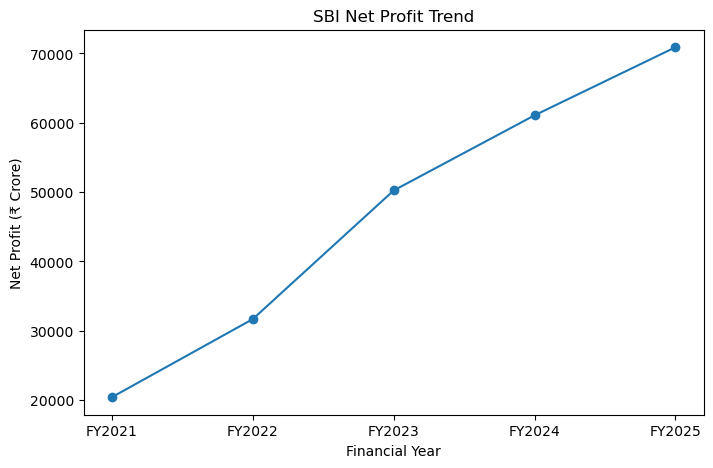

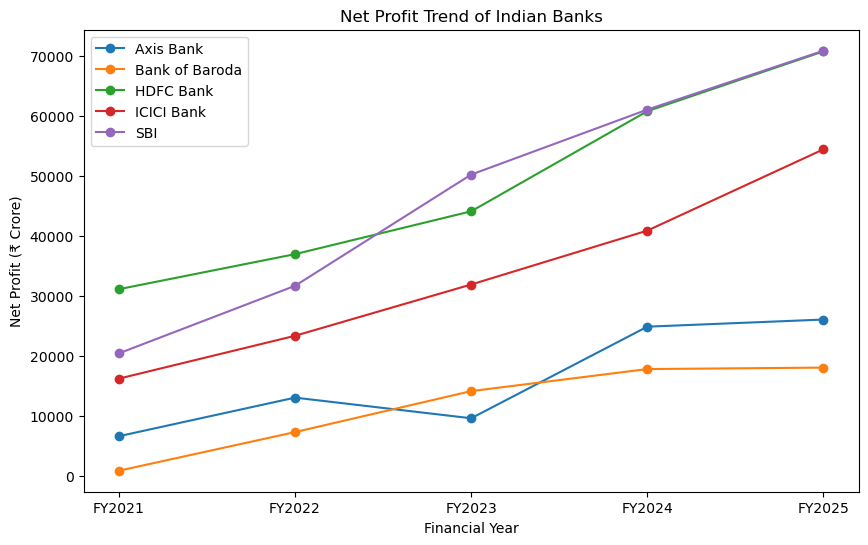

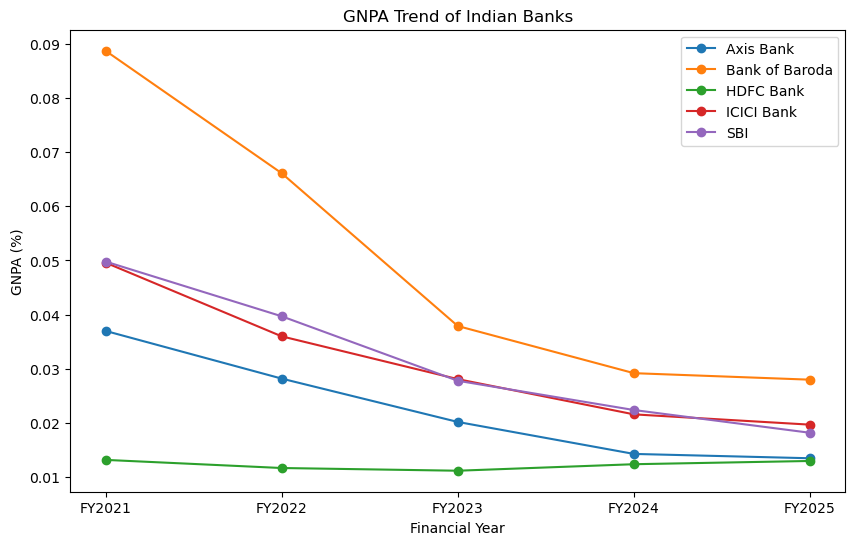

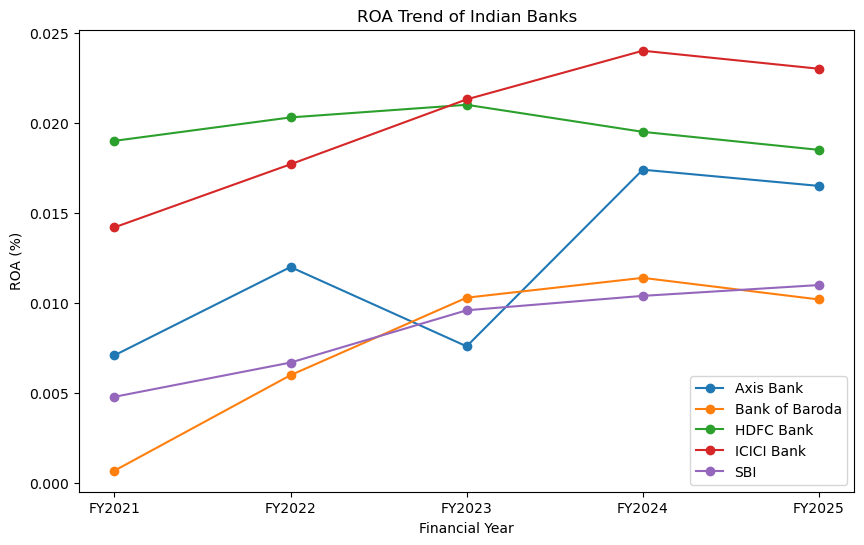

In [ ]:
# ==========================================
# STEP 9
# TREND ANALYSIS
# ==========================================

import matplotlib.pyplot as plt

# 1. Sort data by Bank and Year
df = df.sort_values(["Bank", "Year"])

# 2. Calculate Year-over-Year Growth
df["Profit_Growth"] = df.groupby("Bank")["Net_Profit"].pct_change() * 100

df["Deposit_Growth"] = df.groupby("Bank")["Deposits"].pct_change() * 100

df["Advance_Growth"] = df.groupby("Bank")["Advances"].pct_change() * 100


# 3. Display Profit, Deposit and Advance Growth
print("YEAR-OVER-YEAR GROWTH")
print(df[[
    "Bank",
    "Year",
    "Net_Profit",
    "Profit_Growth",
    "Deposit_Growth",
    "Advance_Growth"
]])


# 4. Create SBI dataset
sbi = df[df["Bank"] == "SBI"].copy()

print("\nSBI TREND")
print(sbi[[
    "Year",
    "Deposits",
    "Advances",
    "Net_Profit",
    "Profit_Growth",
    "Deposit_Growth",
    "Advance_Growth"
]])


# 5. Average growth by bank
growth_summary = df.groupby("Bank")[[
    "Profit_Growth",
    "Deposit_Growth",
    "Advance_Growth"
]].mean()

print("\nAVERAGE GROWTH BY BANK")
print(growth_summary)


# 6. GNPA trend data
print("\nGNPA TREND")
print(df[[
    "Bank",
    "Year",
    "GNPA"
]])


# 7. ROA trend data
print("\nROA TREND")
print(df[[
    "Bank",
    "Year",
    "ROA"
]])


# ==========================================
# CHART 1 - SBI NET PROFIT
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    sbi["Year"],
    sbi["Net_Profit"],
    marker="o"
)

plt.title("SBI Net Profit Trend")
plt.xlabel("Financial Year")
plt.ylabel("Net Profit (₹ Crore)")

plt.show()


# ==========================================
# CHART 2 - NET PROFIT COMPARISON
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["Net_Profit"],
        marker="o",
        label=bank
    )

plt.title("Net Profit Trend of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("Net Profit (₹ Crore)")
plt.legend()

plt.show()


# ==========================================
# CHART 3 - GNPA COMPARISON
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["GNPA"],
        marker="o",
        label=bank
    )

plt.title("GNPA Trend of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("GNPA (%)")
plt.legend()

plt.show()


# ==========================================
# CHART 4 - ROA COMPARISON
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["ROA"],
        marker="o",
        label=bank
    )

plt.title("ROA Trend of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("ROA (%)")
plt.legend()

plt.show()

In [15]:
#STEP 10
# FINANCIAL RATIOS & RISK INDICATORS
# ==========================================

# 1. Advances-to-Deposits Ratio
df["Advances_Deposits_Ratio"] = (
    df["Advances"] / df["Deposits"]
) * 100


# 2. Profit-to-Advances Ratio
df["Profit_to_Advances"] = (
    df["Net_Profit"] / df["Advances"]
) * 100


# 3. Asset Growth
df["Asset_Growth"] = (
    df.groupby("Bank")["Total_Assets"]
    .pct_change()
) * 100


# 4. GNPA absolute change
df["GNPA_Change"] = (
    df.groupby("Bank")["GNPA"]
    .diff()
)


# 5. GNPA percentage change
df["GNPA_Pct_Change"] = (
    df.groupby("Bank")["GNPA"]
    .pct_change()
) * 100


# 6. ROA absolute change
df["ROA_Change"] = (
    df.groupby("Bank")["ROA"]
    .diff()
)


# ==========================================
# BANKING RISK SUMMARY
# ==========================================

risk_summary = df.groupby("Bank")[[
    "Advances_Deposits_Ratio",
    "Profit_to_Advances",
    "Asset_Growth",
    "GNPA",
    "NNPA",
    "ROA",
    "ROE",
    "CAR"
]].mean()

print("BANKING RISK SUMMARY")
print(risk_summary)


# ==========================================
# SBI ANALYSIS
# ==========================================

sbi = df[df["Bank"] == "SBI"].copy()

print("\nSBI RISK ANALYSIS")

print(sbi[[
    "Year",
    "Advances_Deposits_Ratio",
    "Profit_to_Advances",
    "Asset_Growth",
    "GNPA",
    "GNPA_Change",
    "ROA",
    "ROA_Change",
    "CAR"
]])


# ==========================================
# COMPLETE RISK DATA
# ==========================================

risk_data = df[[
    "Bank",
    "Year",
    "GNPA",
    "NNPA",
    "GNPA_Change",
    "GNPA_Pct_Change",
    "ROA",
    "ROA_Change",
    "CAR",
    "Advances_Deposits_Ratio",
    "Asset_Growth"
]]

print("\nCOMPLETE RISK DATA")
print(risk_data)

BANKING RISK SUMMARY
                Advances_Deposits_Ratio  Profit_to_Advances  Asset_Growth  \
Bank                                                                        
Axis Bank                     89.912360            1.785421     13.610766   
Bank of Baroda                78.125964            1.119879     12.676082   
HDFC Bank                     93.412633            2.627565     24.068413   
ICICI Bank                    82.553920            3.113498     14.591056   
SBI                           71.807305            1.382781     10.163065   

                   GNPA     NNPA      ROA      ROE      CAR  
Bank                                                         
Axis Bank       0.02264  0.00564  0.01212  0.11880  0.17580  
Bank of Baroda  0.04998  0.01396  0.00772  0.11440  0.15800  
HDFC Bank       0.01230  0.00338  0.01966  0.16140  0.19060  
ICICI Bank      0.03100  0.00638  0.02004  0.16260  0.17880  
SBI             0.03158  0.00846  0.00850  0.16696  0.14156  

SBI 

In [ ]:
#STEP 11
# FINANCIAL HEALTH & RISK ANALYSIS
# ==========================================

df = df.sort_values(["Bank", "Year"])


# ==========================================
# 1. PERIOD CHANGE ANALYSIS
# FY2021 TO FY2025
# ==========================================

period_analysis = df.groupby("Bank").agg(
    Net_Profit_Start=("Net_Profit", "first"),
    Net_Profit_End=("Net_Profit", "last"),

    Deposits_Start=("Deposits", "first"),
    Deposits_End=("Deposits", "last"),

    Advances_Start=("Advances", "first"),
    Advances_End=("Advances", "last"),

    GNPA_Start=("GNPA", "first"),
    GNPA_End=("GNPA", "last"),

    ROA_Start=("ROA", "first"),
    ROA_End=("ROA", "last"),

    CAR_Start=("CAR", "first"),
    CAR_End=("CAR", "last")
)

print("PERIOD ANALYSIS")
print(period_analysis)


# ==========================================
# 2. CALCULATE NET PROFIT GROWTH
# ==========================================

period_analysis["Net_Profit_Growth_%"] = (
    (period_analysis["Net_Profit_End"]
     - period_analysis["Net_Profit_Start"])
    / period_analysis["Net_Profit_Start"]
) * 100


# ==========================================
# 3. CALCULATE DEPOSIT GROWTH
# ==========================================

period_analysis["Deposit_Growth_%"] = (
    (period_analysis["Deposits_End"]
     - period_analysis["Deposits_Start"])
    / period_analysis["Deposits_Start"]
) * 100


# ==========================================
# 4. CALCULATE ADVANCES GROWTH
# ==========================================

period_analysis["Advance_Growth_%"] = (
    (period_analysis["Advances_End"]
     - period_analysis["Advances_Start"])
    / period_analysis["Advances_Start"]
) * 100


# ==========================================
# 5. GNPA CHANGE
# Percentage-point change
# ==========================================

period_analysis["GNPA_Change_pp"] = (
    period_analysis["GNPA_End"]
    - period_analysis["GNPA_Start"]
)


# ==========================================
# 6. ROA CHANGE
# Percentage-point change
# ==========================================

period_analysis["ROA_Change_pp"] = (
    period_analysis["ROA_End"]
    - period_analysis["ROA_Start"]
)


# ==========================================
# 7. CAR CHANGE
# Percentage-point change
# ==========================================

period_analysis["CAR_Change_pp"] = (
    period_analysis["CAR_End"]
    - period_analysis["CAR_Start"]
)


# ==========================================
# 8. DISPLAY IMPORTANT CHANGES
# ==========================================

print("\nIMPORTANT CHANGES FROM FY2021 TO FY2025")

print(
    period_analysis[[
        "Net_Profit_Growth_%",
        "Deposit_Growth_%",
        "Advance_Growth_%",
        "GNPA_Change_pp",
        "ROA_Change_pp",
        "CAR_Change_pp"
    ]]
)


# ==========================================
# 9. CORRELATION ANALYSIS
# ==========================================

correlation_data = df[[
    "GNPA",
    "NNPA",
    "ROA",
    "ROE",
    "CAR",
    "Profit_Growth",
    "Advance_Growth",
    "Deposit_Growth"
]]

correlation_matrix = correlation_data.corr()

print("\nCORRELATION MATRIX")

print(correlation_matrix)


# ==========================================
# 10. GNPA AND ROA RELATIONSHIP
# ==========================================

print("\nGNPA VS ROA CORRELATION")

print(
    df["GNPA"].corr(df["ROA"])
)


# ==========================================
# 11. GNPA AND PROFIT GROWTH RELATIONSHIP
# ==========================================

print("\nGNPA VS PROFIT GROWTH CORRELATION")

print(
    df["GNPA"].corr(df["Profit_Growth"])
)


# ==========================================
# 12. ADVANCES GROWTH AND GNPA RELATIONSHIP
# ==========================================

print("\nADVANCES GROWTH VS GNPA CORRELATION")

print(
    df["Advance_Growth"].corr(df["GNPA"])
)


# ==========================================
# 13. SBI FINANCIAL HEALTH
# ==========================================

sbi_analysis = df[df["Bank"] == "SBI"].copy()

print("\nSBI FINANCIAL HEALTH")

print(
    sbi_analysis[[
        "Year",
        "Net_Profit",
        "ROA",
        "GNPA",
        "NNPA",
        "CAR",
        "Profit_Growth",
        "Advance_Growth"
    ]]
)


# ==========================================
# 14. HDFC FINANCIAL HEALTH
# ==========================================

hdfc_analysis = df[df["Bank"] == "HDFC Bank"].copy()

print("\nHDFC BANK FINANCIAL HEALTH")

print(
    hdfc_analysis[[
        "Year",
        "Net_Profit",
        "ROA",
        "GNPA",
        "NNPA",
        "CAR",
        "Profit_Growth",
        "Advance_Growth"
    ]]
)


# ==========================================
# 15. FINAL PERIOD SUMMARY
# ==========================================

final_summary = period_analysis[[
    "Net_Profit_Growth_%",
    "Deposit_Growth_%",
    "Advance_Growth_%",
    "GNPA_Change_pp",
    "ROA_Change_pp",
    "CAR_Change_pp"
]]

print("\nFINAL FINANCIAL HEALTH SUMMARY")

print(final_summary)

PERIOD ANALYSIS
                Net_Profit_Start  Net_Profit_End  Deposits_Start  \
Bank                                                               
Axis Bank                   6588           26050          707306   
Bank of Baroda               829           18032          966996   
HDFC Bank                  31117           70792         1335060   
ICICI Bank                 16193           54449          932522   
SBI                        20410           70901         3681277   

                Deposits_End  Advances_Start  Advances_End  GNPA_Start  \
Bank                                                                     
Axis Bank            1170920          623720       1081230      0.0370   
Bank of Baroda       1496690          706306       1237240      0.0887   
HDFC Bank            2710000         1132837       2820000      0.0132   
ICICI Bank           1610348          733729       1340000      0.0496   
SBI                  5382190         2449498       4163312     

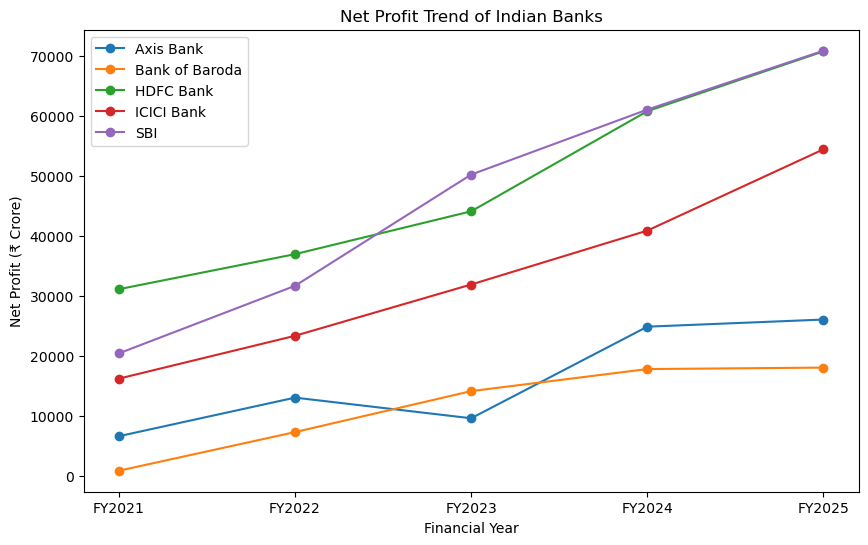

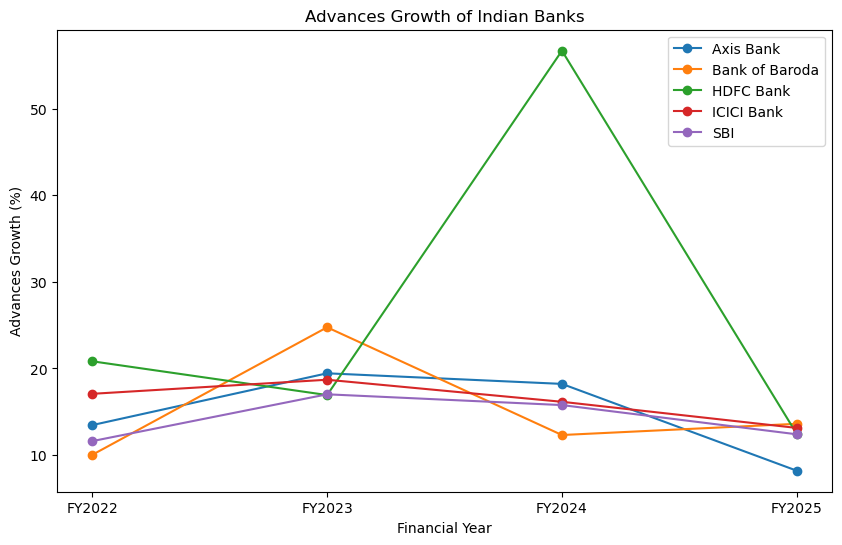

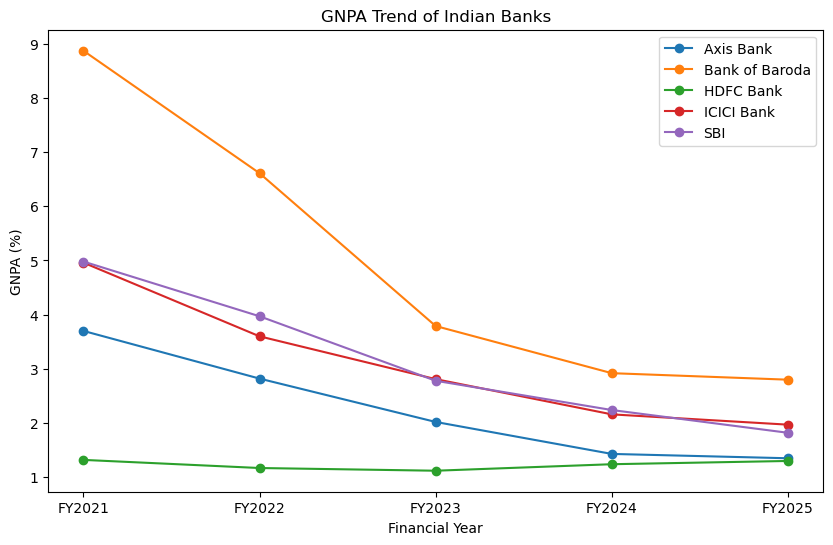

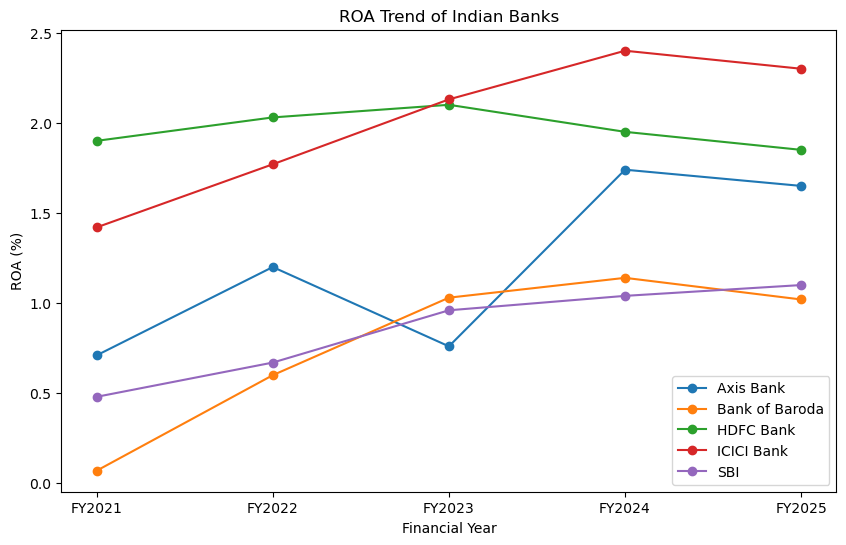

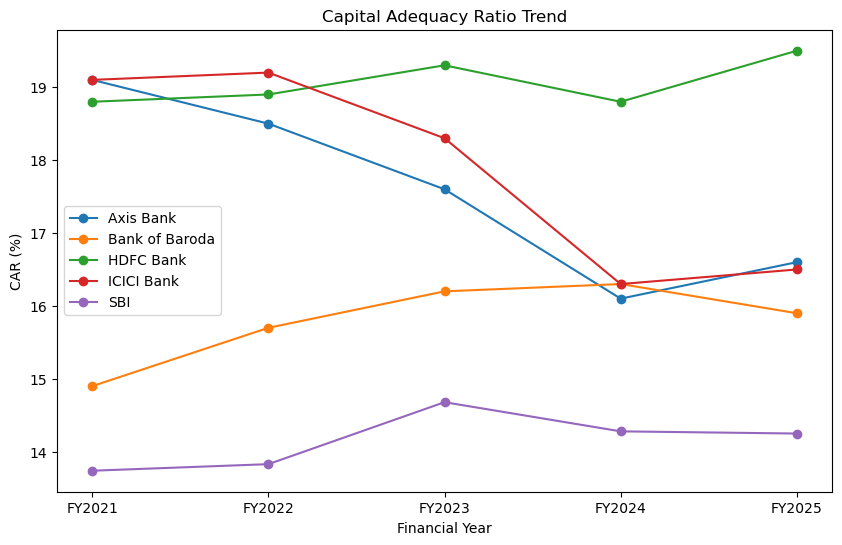

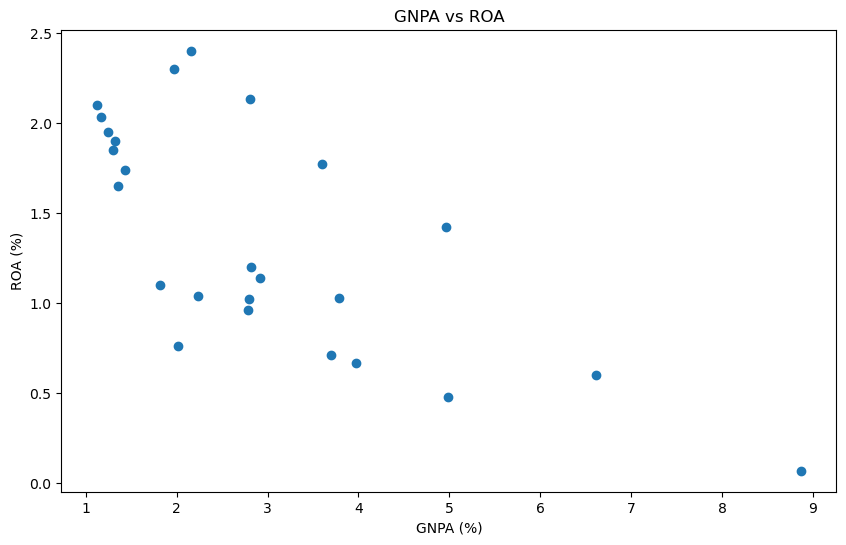

In [17]:
#STEP 12
# VISUALIZATION FOR RISK ANALYTICS
# ==========================================

import matplotlib.pyplot as plt


# ==========================================
# CHART 1
# NET PROFIT TREND
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["Net_Profit"],
        marker="o",
        label=bank
    )

plt.title("Net Profit Trend of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("Net Profit (₹ Crore)")
plt.legend()

plt.show()


# ==========================================
# CHART 2
# ADVANCES GROWTH
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["Advance_Growth"],
        marker="o",
        label=bank
    )

plt.title("Advances Growth of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("Advances Growth (%)")
plt.legend()

plt.show()


# ==========================================
# CHART 3
# GNPA TREND
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["GNPA"] * 100,
        marker="o",
        label=bank
    )

plt.title("GNPA Trend of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("GNPA (%)")
plt.legend()

plt.show()


# ==========================================
# CHART 4
# ROA TREND
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["ROA"] * 100,
        marker="o",
        label=bank
    )

plt.title("ROA Trend of Indian Banks")
plt.xlabel("Financial Year")
plt.ylabel("ROA (%)")
plt.legend()

plt.show()


# ==========================================
# CHART 5
# CAR TREND
# ==========================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[df["Bank"] == bank]

    plt.plot(
        bank_data["Year"],
        bank_data["CAR"] * 100,
        marker="o",
        label=bank
    )

plt.title("Capital Adequacy Ratio Trend")
plt.xlabel("Financial Year")
plt.ylabel("CAR (%)")
plt.legend()

plt.show()


# ==========================================
# CHART 6
# GNPA VS ROA
# ==========================================

plt.figure(figsize=(10, 6))

plt.scatter(
    df["GNPA"] * 100,
    df["ROA"] * 100
)

plt.title("GNPA vs ROA")
plt.xlabel("GNPA (%)")
plt.ylabel("ROA (%)")

plt.show()

In [18]:
# STEP 13
# BANKING RISK INDICATOR SCORE
# ==========================================


# ==========================================
# 1. NORMALIZE GNPA
# Higher GNPA = Higher Risk
# ==========================================

df["GNPA_Risk"] = (
    (df["GNPA"] - df["GNPA"].min())
    /
    (df["GNPA"].max() - df["GNPA"].min())
) * 100


# ==========================================
# 2. NORMALIZE NNPA
# Higher NNPA = Higher Risk
# ==========================================

df["NNPA_Risk"] = (
    (df["NNPA"] - df["NNPA"].min())
    /
    (df["NNPA"].max() - df["NNPA"].min())
) * 100


# ==========================================
# 3. NORMALIZE ROA
# Higher ROA = Lower Risk
# Therefore we reverse the score
# ==========================================

roa_normalized = (
    (df["ROA"] - df["ROA"].min())
    /
    (df["ROA"].max() - df["ROA"].min())
) * 100

df["ROA_Risk"] = 100 - roa_normalized


# ==========================================
# 4. NORMALIZE CAR
# Higher CAR = Lower Risk Indicator
# Therefore we reverse the score
# ==========================================

car_normalized = (
    (df["CAR"] - df["CAR"].min())
    /
    (df["CAR"].max() - df["CAR"].min())
) * 100

df["CAR_Risk"] = 100 - car_normalized


# ==========================================
# 5. CALCULATE OVERALL RISK SCORE
# Equal Weight: 25% each
# ==========================================

df["Risk_Score"] = (
    df["GNPA_Risk"] * 0.25
    +
    df["NNPA_Risk"] * 0.25
    +
    df["ROA_Risk"] * 0.25
    +
    df["CAR_Risk"] * 0.25
)


# ==========================================
# 6. DISPLAY BANK-YEAR RISK SCORE
# ==========================================

print("BANK-YEAR RISK SCORE")

print(
    df[[
        "Bank",
        "Year",
        "GNPA",
        "NNPA",
        "ROA",
        "CAR",
        "GNPA_Risk",
        "NNPA_Risk",
        "ROA_Risk",
        "CAR_Risk",
        "Risk_Score"
    ]]
)


# ==========================================
# 7. AVERAGE RISK SCORE BY BANK
# ==========================================

bank_risk_summary = df.groupby("Bank")[
    [
        "GNPA_Risk",
        "NNPA_Risk",
        "ROA_Risk",
        "CAR_Risk",
        "Risk_Score"
    ]
].mean()

print("\nAVERAGE RISK INDICATOR SUMMARY")

print(bank_risk_summary)


# ==========================================
# 8. RISK SCORE BY YEAR
# ==========================================

year_risk_summary = df.groupby("Year")[
    "Risk_Score"
].mean()

print("\nAVERAGE RISK SCORE BY YEAR")

print(year_risk_summary)

BANK-YEAR RISK SCORE
              Bank    Year    GNPA    NNPA     ROA     CAR   GNPA_Risk  \
20       Axis Bank  FY2021  0.0370  0.0105  0.0071  0.1910   33.290323   
21       Axis Bank  FY2022  0.0282  0.0073  0.0120  0.1850   21.935484   
22       Axis Bank  FY2023  0.0202  0.0039  0.0076  0.1760   11.612903   
23       Axis Bank  FY2024  0.0143  0.0031  0.0174  0.1610    4.000000   
24       Axis Bank  FY2025  0.0135  0.0034  0.0165  0.1660    2.967742   
15  Bank of Baroda  FY2021  0.0887  0.0309  0.0007  0.1490  100.000000   
16  Bank of Baroda  FY2022  0.0661  0.0172  0.0060  0.1570   70.838710   
17  Bank of Baroda  FY2023  0.0379  0.0089  0.0103  0.1620   34.451613   
18  Bank of Baroda  FY2024  0.0292  0.0068  0.0114  0.1630   23.225806   
19  Bank of Baroda  FY2025  0.0280  0.0060  0.0102  0.1590   21.677419   
10       HDFC Bank  FY2021  0.0132  0.0040  0.0190  0.1880    2.580645   
11       HDFC Bank  FY2022  0.0117  0.0032  0.0203  0.1890    0.645161   
12       HDFC Ban

In [20]:
#  STEP 14 — SQL FUNDAMENTALS FOR BANKING ANALYSIS
# ============================================================

import pandas as pd
import sqlite3

# ------------------------------------------------------------
# 1. Create / connect to SQLite database
# ------------------------------------------------------------

connection = sqlite3.connect("project_1_banking.db")


# ------------------------------------------------------------
# 2. Create the bank_data table from our Pandas DataFrame
# ------------------------------------------------------------

df.to_sql(
    "bank_data",
    connection,
    if_exists="replace",
    index=False
)

print("bank_data table created successfully!")


# ------------------------------------------------------------
# 3. Check that the table exists
# ------------------------------------------------------------

query = """
SELECT name
FROM sqlite_master
WHERE type = 'table';
"""

print("\nTABLES IN DATABASE:")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 4. Show all data
# ------------------------------------------------------------

query = """
SELECT *
FROM bank_data;
"""

print("\n1. ALL DATA")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 5. Show SBI data
# ------------------------------------------------------------

query = """
SELECT Bank, Year, Deposits, Advances, Net_Profit
FROM bank_data
WHERE Bank = 'SBI';
"""

print("\n2. SBI DATA")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 6. Show FY2025 data
# ------------------------------------------------------------

query = """
SELECT Bank, Year, Net_Profit, GNPA, ROA, CAR
FROM bank_data
WHERE Year = 'FY2025';
"""

print("\n3. FY2025 DATA")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 7. Average Net Profit by bank
# ------------------------------------------------------------

query = """
SELECT Bank, AVG(Net_Profit) AS Average_Net_Profit
FROM bank_data
GROUP BY Bank;
"""

print("\n4. AVERAGE NET PROFIT")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 8. Average GNPA by bank
# ------------------------------------------------------------

query = """
SELECT Bank, AVG(GNPA) AS Average_GNPA
FROM bank_data
GROUP BY Bank;
"""

print("\n5. AVERAGE GNPA")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 9. Average ROA and CAR by bank
# ------------------------------------------------------------

query = """
SELECT
    Bank,
    AVG(ROA) AS Average_ROA,
    AVG(CAR) AS Average_CAR
FROM bank_data
GROUP BY Bank;
"""

print("\n6. AVERAGE ROA AND CAR")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 10. Minimum and Maximum GNPA
# ------------------------------------------------------------

query = """
SELECT
    Bank,
    MIN(GNPA) AS Minimum_GNPA,
    MAX(GNPA) AS Maximum_GNPA
FROM bank_data
GROUP BY Bank;
"""

print("\n7. MINIMUM AND MAXIMUM GNPA")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 11. Count number of years for each bank
# ------------------------------------------------------------

query = """
SELECT
    Bank,
    COUNT(*) AS Number_of_Years
FROM bank_data
GROUP BY Bank;
"""

print("\n8. NUMBER OF YEARS")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 12. Close database connection
# ------------------------------------------------------------

connection.close()

print("\nStep 14 completed successfully!")

bank_data table created successfully!

TABLES IN DATABASE:
        name
0  bank_data

1. ALL DATA
              Bank    Year  Deposits  Advances  Total_Assets  Net_Profit  \
0        Axis Bank  FY2021    707306    623720        996118        6588   
1        Axis Bank  FY2022    821721    707696       1175178       13025   
2        Axis Bank  FY2023    946945    845303       1344418        9580   
3        Axis Bank  FY2024   1067100    999330       1518240       24861   
4        Axis Bank  FY2025   1170920   1081230       1656960       26050   
5   Bank of Baroda  FY2021    966996    706306       1155365         829   
6   Bank of Baroda  FY2022   1045939    777155       1278000        7272   
7   Bank of Baroda  FY2023   1203688    969548       1458562       14110   
8   Bank of Baroda  FY2024   1359980   1088980       1654780       17789   
9   Bank of Baroda  FY2025   1496690   1237240       1861770       18032   
10       HDFC Bank  FY2021   1335060   1132837       1746871      

In [21]:

# STEP 15 — INTERMEDIATE SQL FOR BANKING RISK ANALYSIS
# ============================================================

import pandas as pd
import sqlite3


# ------------------------------------------------------------
# 1. Connect to SQLite database
# ------------------------------------------------------------

connection = sqlite3.connect("project_1_banking.db")


# ------------------------------------------------------------
# 2. Refresh the SQL table from the current Pandas DataFrame
# ------------------------------------------------------------

df.to_sql(
    "bank_data",
    connection,
    if_exists="replace",
    index=False
)

print("bank_data table refreshed successfully!")


# ============================================================
# 3. CASE WHEN — GNPA Risk Classification
# ============================================================

query = """
SELECT
    Bank,
    Year,
    GNPA,
    CASE
        WHEN GNPA > 0.03 THEN 'Higher GNPA'
        ELSE 'Lower GNPA'
    END AS GNPA_Risk_Level
FROM bank_data;
"""

print("\n1. GNPA RISK CLASSIFICATION")
print(pd.read_sql_query(query, connection))


# ============================================================
# 4. CASE WHEN — ROA Classification
# ============================================================

query = """
SELECT
    Bank,
    Year,
    ROA,
    CASE
        WHEN ROA >= 0.01 THEN 'Higher ROA'
        ELSE 'Lower ROA'
    END AS ROA_Level
FROM bank_data;
"""

print("\n2. ROA CLASSIFICATION")
print(pd.read_sql_query(query, connection))


# ============================================================
# 5. Multiple Conditions — Find higher-risk observations
# ============================================================

query = """
SELECT
    Bank,
    Year,
    GNPA,
    NNPA,
    ROA,
    CAR
FROM bank_data
WHERE GNPA > 0.03
AND NNPA > 0.01;
"""

print("\n3. HIGHER GNPA AND HIGHER NNPA")
print(pd.read_sql_query(query, connection))


# ============================================================
# 6. CASE WHEN — Overall Simple Risk Category
# ============================================================

query = """
SELECT
    Bank,
    Year,
    GNPA,
    NNPA,
    ROA,
    CAR,
    CASE
        WHEN GNPA > 0.03 AND NNPA > 0.01 THEN 'Higher Risk'
        WHEN GNPA > 0.03 OR NNPA > 0.01 THEN 'Moderate Risk'
        ELSE 'Lower Risk'
    END AS Risk_Category
FROM bank_data;
"""

print("\n4. OVERALL RISK CATEGORY")
print(pd.read_sql_query(query, connection))


# ============================================================
# 7. Calculated Column — Advances to Deposits Ratio
# ============================================================

query = """
SELECT
    Bank,
    Year,
    Deposits,
    Advances,
    (Advances / Deposits) * 100 AS Advances_Deposits_Ratio
FROM bank_data;
"""

print("\n5. ADVANCES TO DEPOSITS RATIO")
print(pd.read_sql_query(query, connection))


# ============================================================
# 8. Calculated Column — Profit to Advances
# ============================================================

query = """
SELECT
    Bank,
    Year,
    Net_Profit,
    Advances,
    (Net_Profit / Advances) * 100 AS Profit_to_Advances
FROM bank_data;
"""

print("\n6. PROFIT TO ADVANCES")
print(pd.read_sql_query(query, connection))


# ============================================================
# 9. HAVING — Banks with Average GNPA above 3%
# ============================================================

query = """
SELECT
    Bank,
    AVG(GNPA) AS Average_GNPA
FROM bank_data
GROUP BY Bank
HAVING AVG(GNPA) > 0.03;
"""

print("\n7. BANKS WITH AVERAGE GNPA ABOVE 3%")
print(pd.read_sql_query(query, connection))


# ============================================================
# 10. HAVING — Banks with Average ROA above 1%
# ============================================================

query = """
SELECT
    Bank,
    AVG(ROA) AS Average_ROA
FROM bank_data
GROUP BY Bank
HAVING AVG(ROA) > 0.01;
"""

print("\n8. BANKS WITH AVERAGE ROA ABOVE 1%")
print(pd.read_sql_query(query, connection))


# ============================================================
# 11. Bank-level risk summary
# ============================================================

query = """
SELECT
    Bank,
    AVG(GNPA) AS Average_GNPA,
    AVG(NNPA) AS Average_NNPA,
    AVG(ROA) AS Average_ROA,
    AVG(CAR) AS Average_CAR,
    
    CASE
        WHEN AVG(GNPA) > 0.03
             AND AVG(NNPA) > 0.01
        THEN 'Higher Risk'
        
        WHEN AVG(GNPA) > 0.03
             OR AVG(NNPA) > 0.01
        THEN 'Moderate Risk'
        
        ELSE 'Lower Risk'
    END AS Risk_Category

FROM bank_data
GROUP BY Bank;
"""

print("\n9. BANK-LEVEL RISK SUMMARY")
print(pd.read_sql_query(query, connection))


# ============================================================
# 12. FY2025 — Compare all banks
# ============================================================

query = """
SELECT
    Bank,
    Net_Profit,
    GNPA,
    NNPA,
    ROA,
    ROE,
    CAR
FROM bank_data
WHERE Year = 'FY2025'
ORDER BY Net_Profit DESC;
"""

print("\n10. FY2025 BANK COMPARISON")
print(pd.read_sql_query(query, connection))


# ============================================================
# 13. Close database connection
# ============================================================

connection.close()

print("\nStep 15 completed successfully!")

bank_data table refreshed successfully!

1. GNPA RISK CLASSIFICATION
              Bank    Year    GNPA GNPA_Risk_Level
0        Axis Bank  FY2021  0.0370     Higher GNPA
1        Axis Bank  FY2022  0.0282      Lower GNPA
2        Axis Bank  FY2023  0.0202      Lower GNPA
3        Axis Bank  FY2024  0.0143      Lower GNPA
4        Axis Bank  FY2025  0.0135      Lower GNPA
5   Bank of Baroda  FY2021  0.0887     Higher GNPA
6   Bank of Baroda  FY2022  0.0661     Higher GNPA
7   Bank of Baroda  FY2023  0.0379     Higher GNPA
8   Bank of Baroda  FY2024  0.0292      Lower GNPA
9   Bank of Baroda  FY2025  0.0280      Lower GNPA
10       HDFC Bank  FY2021  0.0132      Lower GNPA
11       HDFC Bank  FY2022  0.0117      Lower GNPA
12       HDFC Bank  FY2023  0.0112      Lower GNPA
13       HDFC Bank  FY2024  0.0124      Lower GNPA
14       HDFC Bank  FY2025  0.0130      Lower GNPA
15      ICICI Bank  FY2021  0.0496     Higher GNPA
16      ICICI Bank  FY2022  0.0360     Higher GNPA
17      ICICI

In [22]:
# ADVANCED SQL FOR BANKING ANALYSIS
# ============================================================

import pandas as pd
import sqlite3


# ------------------------------------------------------------
# 1. Connect to SQLite database
# ------------------------------------------------------------

connection = sqlite3.connect("project_1_banking.db")


# ------------------------------------------------------------
# 2. Refresh SQL table from current Pandas DataFrame
# ------------------------------------------------------------

df.to_sql(
    "bank_data",
    connection,
    if_exists="replace",
    index=False
)

print("bank_data table refreshed successfully!")


# ============================================================
# 3. SELF JOIN
# Compare FY2021 and FY2025 Net Profit
# ============================================================

query = """
SELECT
    start.Bank,
    start.Net_Profit AS FY2021_Net_Profit,
    end.Net_Profit AS FY2025_Net_Profit
FROM bank_data AS start
JOIN bank_data AS end
    ON start.Bank = end.Bank
WHERE start.Year = 'FY2021'
AND end.Year = 'FY2025';
"""

print("\n1. FY2021 VS FY2025 NET PROFIT")
print(pd.read_sql_query(query, connection))


# ============================================================
# 4. SELF JOIN + CALCULATE 5-YEAR PROFIT GROWTH
# ============================================================

query = """
SELECT
    start.Bank,
    start.Net_Profit AS FY2021_Net_Profit,
    end.Net_Profit AS FY2025_Net_Profit,

    (
        (end.Net_Profit - start.Net_Profit)
        / start.Net_Profit
    ) * 100 AS Five_Year_Profit_Growth

FROM bank_data AS start

JOIN bank_data AS end
    ON start.Bank = end.Bank

WHERE start.Year = 'FY2021'
AND end.Year = 'FY2025'

ORDER BY Five_Year_Profit_Growth DESC;
"""

print("\n2. FIVE-YEAR NET PROFIT GROWTH")
print(pd.read_sql_query(query, connection))


# ============================================================
# 5. SUBQUERY
# Find observations where Net Profit is above
# the overall average Net Profit
# ============================================================

query = """
SELECT
    Bank,
    Year,
    Net_Profit
FROM bank_data
WHERE Net_Profit >
      (
          SELECT AVG(Net_Profit)
          FROM bank_data
      )
ORDER BY Net_Profit DESC;
"""

print("\n3. NET PROFIT ABOVE OVERALL AVERAGE")
print(pd.read_sql_query(query, connection))


# ============================================================
# 6. SUBQUERY
# Find observations where GNPA is above
# the overall average GNPA
# ============================================================

query = """
SELECT
    Bank,
    Year,
    GNPA
FROM bank_data
WHERE GNPA >
      (
          SELECT AVG(GNPA)
          FROM bank_data
      )
ORDER BY GNPA DESC;
"""

print("\n4. GNPA ABOVE OVERALL AVERAGE")
print(pd.read_sql_query(query, connection))


# ============================================================
# 7. LAG()
# Calculate year-over-year Net Profit change
# ============================================================

query = """
SELECT
    Bank,
    Year,
    Net_Profit,

    LAG(Net_Profit) OVER (
        PARTITION BY Bank
        ORDER BY Year
    ) AS Previous_Year_Profit

FROM bank_data
ORDER BY Bank, Year;
"""

print("\n5. PREVIOUS YEAR NET PROFIT")
print(pd.read_sql_query(query, connection))


# ============================================================
# 8. LAG() + CALCULATE PROFIT GROWTH
# ============================================================

query = """
SELECT
    Bank,
    Year,
    Net_Profit,

    LAG(Net_Profit) OVER (
        PARTITION BY Bank
        ORDER BY Year
    ) AS Previous_Year_Profit,

    (
        (
            Net_Profit -
            LAG(Net_Profit) OVER (
                PARTITION BY Bank
                ORDER BY Year
            )
        )
        /
        LAG(Net_Profit) OVER (
            PARTITION BY Bank
            ORDER BY Year
        )
    ) * 100 AS Profit_Growth_Percent

FROM bank_data
ORDER BY Bank, Year;
"""

print("\n6. YEAR-OVER-YEAR PROFIT GROWTH")
print(pd.read_sql_query(query, connection))


# ============================================================
# 9. RANK BANKS BY FY2025 NET PROFIT
# ============================================================

query = """
SELECT
    Bank,
    Net_Profit,

    RANK() OVER (
        ORDER BY Net_Profit DESC
    ) AS Profit_Rank

FROM bank_data

WHERE Year = 'FY2025'

ORDER BY Profit_Rank;
"""

print("\n7. FY2025 NET PROFIT RANKING")
print(pd.read_sql_query(query, connection))


# ============================================================
# 10. RANK BANKS BY FY2025 ROA
# ============================================================

query = """
SELECT
    Bank,
    ROA,

    RANK() OVER (
        ORDER BY ROA DESC
    ) AS ROA_Rank

FROM bank_data

WHERE Year = 'FY2025'

ORDER BY ROA_Rank;
"""

print("\n8. FY2025 ROA RANKING")
print(pd.read_sql_query(query, connection))


# ============================================================
# 11. RANK BANKS BY FY2025 GNPA
# Lower GNPA appears first
# ============================================================

query = """
SELECT
    Bank,
    GNPA,

    RANK() OVER (
        ORDER BY GNPA ASC
    ) AS GNPA_Rank

FROM bank_data

WHERE Year = 'FY2025'

ORDER BY GNPA_Rank;
"""

print("\n9. FY2025 GNPA RANKING")
print(pd.read_sql_query(query, connection))


# ============================================================
# 12. Combine multiple indicators for FY2025
# ============================================================

query = """
SELECT
    Bank,
    Net_Profit,
    ROA,
    GNPA,
    NNPA,
    CAR,

    RANK() OVER (
        ORDER BY Net_Profit DESC
    ) AS Profit_Rank,

    RANK() OVER (
        ORDER BY ROA DESC
    ) AS ROA_Rank,

    RANK() OVER (
        ORDER BY GNPA ASC
    ) AS GNPA_Rank

FROM bank_data

WHERE Year = 'FY2025'

ORDER BY Profit_Rank;
"""

print("\n10. FY2025 MULTI-INDICATOR ANALYSIS")
print(pd.read_sql_query(query, connection))


# ------------------------------------------------------------
# 13. Close database connection
# ------------------------------------------------------------

connection.close()

print("\nStep 16 completed successfully!")

bank_data table refreshed successfully!

1. FY2021 VS FY2025 NET PROFIT
             Bank  FY2021_Net_Profit  FY2025_Net_Profit
0       Axis Bank               6588              26050
1  Bank of Baroda                829              18032
2       HDFC Bank              31117              70792
3      ICICI Bank              16193              54449
4             SBI              20410              70901

2. FIVE-YEAR NET PROFIT GROWTH
             Bank  FY2021_Net_Profit  FY2025_Net_Profit  \
0  Bank of Baroda                829              18032   
1       Axis Bank               6588              26050   
2      ICICI Bank              16193              54449   
3             SBI              20410              70901   
4       HDFC Bank              31117              70792   

   Five_Year_Profit_Growth  
0                     2000  
1                      200  
2                      200  
3                      200  
4                      100  

3. NET PROFIT ABOVE OVERALL AV

In [25]:
# ============================================================
# STEP 17 — STATISTICAL ANALYSIS FOR BANKING RISK
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Correct column names
# ------------------------------------------------------------

df = df.rename(columns={
    "Provision Coverage Ratio": "Provision_Coverage_Ratio",
    "Cost/Income Ratio": "Cost_Income_Ratio"
})


# ------------------------------------------------------------
# 2. Check column names
# ------------------------------------------------------------

print("\nCOLUMN NAMES:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 3. Select important financial variables
# ------------------------------------------------------------

financial_columns = [
    "Deposits",
    "Advances",
    "Total_Assets",
    "Net_Profit",
    "ROA",
    "ROE",
    "GNPA",
    "NNPA",
    "CAR",
    "NIM",
    "Provision_Coverage_Ratio",
    "Cost_Income_Ratio"
]


# ------------------------------------------------------------
# 4. Basic statistical summary
# ------------------------------------------------------------

print("\n1. BASIC STATISTICAL SUMMARY")

print(df[financial_columns].describe())


# ------------------------------------------------------------
# 5. Mean
# ------------------------------------------------------------

print("\n2. MEAN")

mean_values = df[financial_columns].mean()

print(mean_values)


# ------------------------------------------------------------
# 6. Median
# ------------------------------------------------------------

print("\n3. MEDIAN")

median_values = df[financial_columns].median()

print(median_values)


# ------------------------------------------------------------
# 7. Variance
# ------------------------------------------------------------

print("\n4. VARIANCE")

variance_values = df[financial_columns].var()

print(variance_values)


# ------------------------------------------------------------
# 8. Standard Deviation
# ------------------------------------------------------------

print("\n5. STANDARD DEVIATION")

std_values = df[financial_columns].std()

print(std_values)


# ------------------------------------------------------------
# 9. Minimum
# ------------------------------------------------------------

print("\n6. MINIMUM VALUES")

minimum_values = df[financial_columns].min()

print(minimum_values)


# ------------------------------------------------------------
# 10. Maximum
# ------------------------------------------------------------

print("\n7. MAXIMUM VALUES")

maximum_values = df[financial_columns].max()

print(maximum_values)


# ------------------------------------------------------------
# 11. Range
# ------------------------------------------------------------

print("\n8. RANGE")

range_values = (
    df[financial_columns].max()
    - df[financial_columns].min()
)

print(range_values)


# ------------------------------------------------------------
# 12. Statistics by Bank
# ------------------------------------------------------------

print("\n9. STATISTICS BY BANK")

bank_statistics = df.groupby("Bank")[
    ["Net_Profit", "ROA", "ROE", "GNPA", "NNPA", "CAR"]
].agg([
    "mean",
    "median",
    "std",
    "min",
    "max"
])

print(bank_statistics)


# ------------------------------------------------------------
# 13. Correlation Matrix
# ------------------------------------------------------------

print("\n10. CORRELATION MATRIX")

correlation_matrix = df[
    [
        "Net_Profit",
        "Advances",
        "Deposits",
        "ROA",
        "ROE",
        "GNPA",
        "NNPA",
        "CAR",
        "NIM"
    ]
].corr()

print(correlation_matrix)


# ------------------------------------------------------------
# 14. Important Correlations
# ------------------------------------------------------------

print("\n11. IMPORTANT CORRELATIONS")

print(
    "GNPA vs ROA:",
    df["GNPA"].corr(df["ROA"])
)

print(
    "GNPA vs Net Profit:",
    df["GNPA"].corr(df["Net_Profit"])
)

print(
    "Advances vs Net Profit:",
    df["Advances"].corr(df["Net_Profit"])
)

print(
    "CAR vs ROA:",
    df["CAR"].corr(df["ROA"])
)


# ------------------------------------------------------------
# 15. GNPA Outlier Analysis
# ------------------------------------------------------------

print("\n12. GNPA OUTLIER ANALYSIS")

Q1 = df["GNPA"].quantile(0.25)

Q3 = df["GNPA"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)


gnpa_outliers = df[
    (df["GNPA"] < lower_bound)
    |
    (df["GNPA"] > upper_bound)
]

print("\nGNPA OUTLIERS:")

print(
    gnpa_outliers[
        ["Bank", "Year", "GNPA"]
    ]
)


# ------------------------------------------------------------
# 16. Net Profit Outlier Analysis
# ------------------------------------------------------------

print("\n13. NET PROFIT OUTLIER ANALYSIS")

Q1_profit = df["Net_Profit"].quantile(0.25)

Q3_profit = df["Net_Profit"].quantile(0.75)

IQR_profit = Q3_profit - Q1_profit

lower_profit = Q1_profit - 1.5 * IQR_profit

upper_profit = Q3_profit + 1.5 * IQR_profit

print("Q1:", Q1_profit)
print("Q3:", Q3_profit)
print("IQR:", IQR_profit)
print("Lower Bound:", lower_profit)
print("Upper Bound:", upper_profit)


profit_outliers = df[
    (df["Net_Profit"] < lower_profit)
    |
    (df["Net_Profit"] > upper_profit)
]

print("\nNET PROFIT OUTLIERS:")

print(
    profit_outliers[
        ["Bank", "Year", "Net_Profit"]
    ]
)


# ------------------------------------------------------------
# 17. Net Profit Standard Deviation by Bank
# ------------------------------------------------------------

print("\n14. NET PROFIT STANDARD DEVIATION BY BANK")

profit_std_by_bank = df.groupby("Bank")[
    "Net_Profit"
].std()

print(profit_std_by_bank)


# ------------------------------------------------------------
# 18. GNPA Standard Deviation by Bank
# ------------------------------------------------------------

print("\n15. GNPA STANDARD DEVIATION BY BANK")

gnpa_std_by_bank = df.groupby("Bank")[
    "GNPA"
].std()

print(gnpa_std_by_bank)


print("\nStep 17 completed successfully!")


COLUMN NAMES:
['Bank', 'Year', 'Deposits', 'Advances', 'Total_Assets', 'Net_Profit', 'ROA', 'ROE', 'GNPA', 'NNPA', 'CAR', 'NIM', 'Provision_Coverage_Ratio', 'Cost_Income_Ratio', 'Profit_Growth', 'Deposit_Growth', 'Advance_Growth', 'Advances_Deposits_Ratio', 'Profit_to_Advances', 'Asset_Growth', 'GNPA_Change', 'GNPA_Pct_Change', 'ROA_Change', 'GNPA_Risk', 'NNPA_Risk', 'ROA_Risk', 'CAR_Risk', 'Risk_Score']

1. BASIC STATISTICAL SUMMARY
           Deposits      Advances  Total_Assets    Net_Profit        ROA  \
count  2.500000e+01  2.500000e+01  2.500000e+01     25.000000  25.000000   
mean   1.972437e+06  1.594144e+06  2.566406e+06  31319.440000   0.013608   
std    1.389169e+06  1.025457e+06  1.724972e+06  20538.350944   0.006370   
min    7.073060e+05  6.237200e+05  9.961180e+05    829.000000   0.000700   
25%    1.064572e+06  8.590200e+05  1.411298e+06  16193.000000   0.009600   
50%    1.359980e+06  1.132837e+06  1.746871e+06  26050.000000   0.012000   
75%    2.380000e+06  2.449498

In [26]:
# ============================================================
# STEP 18 — STATISTICAL TESTING & REGRESSION
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import statsmodels.api as sm


# ------------------------------------------------------------
# 1. Make sure important columns are numeric
# ------------------------------------------------------------

analysis_columns = [
    "GNPA",
    "NNPA",
    "ROA",
    "ROE",
    "CAR",
    "NIM",
    "Net_Profit",
    "Advances",
    "Deposits"
]

for col in analysis_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# 2. Pearson Correlation Test
#    GNPA vs ROA
# ============================================================

correlation_data = df[
    ["GNPA", "ROA"]
].dropna()

correlation, p_value = pearsonr(
    correlation_data["GNPA"],
    correlation_data["ROA"]
)

print("\n1. PEARSON CORRELATION TEST")
print("--------------------------------")
print("Correlation:", correlation)
print("P-value:", p_value)


# ------------------------------------------------------------
# Interpret the statistical test
# ------------------------------------------------------------

if p_value < 0.05:
    print(
        "Result: Evidence against the null hypothesis "
        "at the 5% significance level."
    )
else:
    print(
        "Result: Insufficient evidence to reject the "
        "null hypothesis at the 5% significance level."
    )


# ============================================================
# 3. Pearson Correlation Test
#    GNPA vs Net Profit
# ============================================================

correlation_data = df[
    ["GNPA", "Net_Profit"]
].dropna()

correlation, p_value = pearsonr(
    correlation_data["GNPA"],
    correlation_data["Net_Profit"]
)

print("\n2. GNPA VS NET PROFIT")
print("--------------------------------")
print("Correlation:", correlation)
print("P-value:", p_value)


if p_value < 0.05:
    print(
        "Result: Evidence against the null hypothesis "
        "at the 5% significance level."
    )
else:
    print(
        "Result: Insufficient evidence to reject the "
        "null hypothesis at the 5% significance level."
    )


# ============================================================
# 4. Pearson Correlation Test
#    CAR vs ROA
# ============================================================

correlation_data = df[
    ["CAR", "ROA"]
].dropna()

correlation, p_value = pearsonr(
    correlation_data["CAR"],
    correlation_data["ROA"]
)

print("\n3. CAR VS ROA")
print("--------------------------------")
print("Correlation:", correlation)
print("P-value:", p_value)


if p_value < 0.05:
    print(
        "Result: Evidence against the null hypothesis "
        "at the 5% significance level."
    )
else:
    print(
        "Result: Insufficient evidence to reject the "
        "null hypothesis at the 5% significance level."
    )


# ============================================================
# 5. SIMPLE LINEAR REGRESSION
#    ROA explained by GNPA
# ============================================================

regression_data = df[
    ["ROA", "GNPA"]
].dropna()

X = regression_data[
    ["GNPA"]
]

y = regression_data[
    "ROA"
]

# Add intercept
X = sm.add_constant(X)

simple_model = sm.OLS(
    y,
    X
).fit()

print("\n4. SIMPLE LINEAR REGRESSION")
print("--------------------------------")

print(
    simple_model.summary()
)


# ============================================================
# 6. Display Simple Regression Coefficients
# ============================================================

print("\n5. SIMPLE REGRESSION COEFFICIENTS")
print("--------------------------------")

print(
    simple_model.params
)


# ============================================================
# 7. SIMPLE REGRESSION R-SQUARED
# ============================================================

print("\n6. SIMPLE REGRESSION R-SQUARED")
print("--------------------------------")

print(
    "R-squared:",
    simple_model.rsquared
)


# ============================================================
# 8. MULTIPLE LINEAR REGRESSION
#
#    ROA = GNPA + CAR + NIM
# ============================================================

regression_data = df[
    [
        "ROA",
        "GNPA",
        "CAR",
        "NIM"
    ]
].dropna()

X = regression_data[
    [
        "GNPA",
        "CAR",
        "NIM"
    ]
]

y = regression_data[
    "ROA"
]

# Add intercept
X = sm.add_constant(X)

multiple_model = sm.OLS(
    y,
    X
).fit()


# ============================================================
# 9. Multiple Regression Results
# ============================================================

print("\n7. MULTIPLE LINEAR REGRESSION")
print("--------------------------------")

print(
    multiple_model.summary()
)


# ============================================================
# 10. Multiple Regression Coefficients
# ============================================================

print("\n8. MULTIPLE REGRESSION COEFFICIENTS")
print("--------------------------------")

print(
    multiple_model.params
)


# ============================================================
# 11. P-VALUES OF REGRESSION VARIABLES
# ============================================================

print("\n9. REGRESSION P-VALUES")
print("--------------------------------")

print(
    multiple_model.pvalues
)


# ============================================================
# 12. R-SQUARED
# ============================================================

print("\n10. MULTIPLE REGRESSION R-SQUARED")
print("--------------------------------")

print(
    "R-squared:",
    multiple_model.rsquared
)

print(
    "Adjusted R-squared:",
    multiple_model.rsquared_adj
)


# ============================================================
# 13. Predicted ROA
# ============================================================

predictions = multiple_model.predict(X)

regression_results = regression_data.copy()

regression_results[
    "Predicted_ROA"
] = predictions

print("\n11. ACTUAL VS PREDICTED ROA")
print("--------------------------------")

print(
    regression_results[
        [
            "ROA",
            "Predicted_ROA"
        ]
    ]
)


print("\nStep 18 completed successfully!")


1. PEARSON CORRELATION TEST
--------------------------------
Correlation: -0.7089689020482369
P-value: 7.27151792188772e-05
Result: Evidence against the null hypothesis at the 5% significance level.

2. GNPA VS NET PROFIT
--------------------------------
Correlation: -0.6136807476334885
P-value: 0.001103812161589227
Result: Evidence against the null hypothesis at the 5% significance level.

3. CAR VS ROA
--------------------------------
Correlation: 0.5626846595854174
P-value: 0.0034103821810678924
Result: Evidence against the null hypothesis at the 5% significance level.

4. SIMPLE LINEAR REGRESSION
--------------------------------
                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.503
Model:                            OLS   Adj. R-squared:                  0.481
Method:                 Least Squares   F-statistic:                     23.24
Date:                Thu, 01 Oct 2026   Pr


1. REGRESSION MODEL
--------------------------------
                            OLS Regression Results                            
Dep. Variable:                    ROA   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.813
Method:                 Least Squares   F-statistic:                     35.80
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           1.93e-08
Time:                        17:38:11   Log-Likelihood:                 114.08
No. Observations:                  25   AIC:                            -220.2
Df Residuals:                      21   BIC:                            -215.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

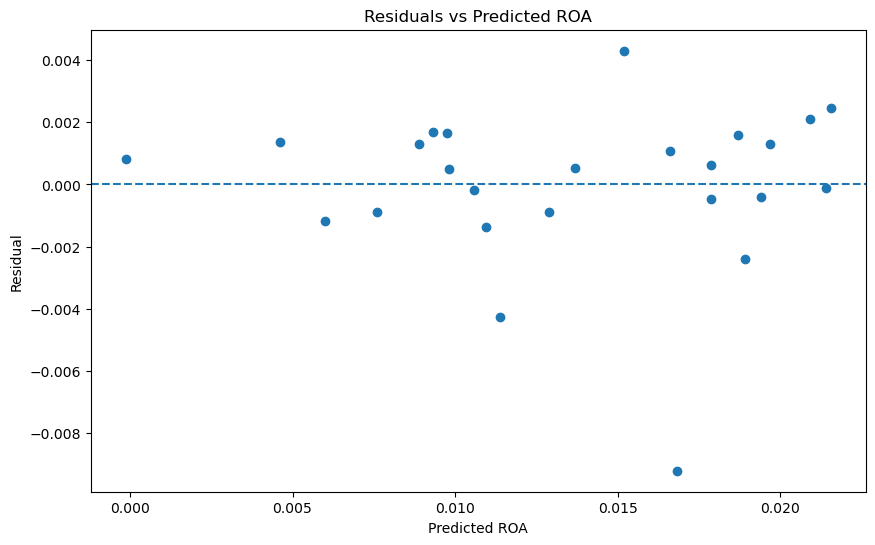


4. BREUSCH-PAGAN TEST
--------------------------------
LM Statistic: 0.8286930142185067
LM P-value: 0.8425924446675457
F Statistic: 0.2399891368282999
F P-value: 0.8674547112461974
Result: Insufficient evidence of heteroscedasticity at the 5% significance level.

5. VARIANCE INFLATION FACTOR (VIF)
--------------------------------
  Variable        VIF
0     GNPA   3.481607
1      CAR  95.140349
2      NIM  83.869863

6. VIF INTERPRETATION
--------------------------------
GNPA → Lower multicollinearity concern
CAR → High multicollinearity concern
NIM → High multicollinearity concern

7. JARQUE-BERA TEST
--------------------------------
JB Statistic: 39.51829840095821
P-value: 2.622470038578055e-09
Result: Evidence against normality of residuals at the 5% significance level.

8. DURBIN-WATSON STATISTIC
--------------------------------
Durbin-Watson: 1.4320198511658524

9. MODEL DIAGNOSTIC SUMMARY
--------------------------------
R-squared: 0.8364625353502191
Adjusted R-squared: 0.813100

In [27]:
# ============================================================
# STEP 19 — REGRESSION DIAGNOSTICS & MODEL VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.stats.diagnostic import (
    het_breuschpagan
)

from statsmodels.stats.stattools import (
    durbin_watson,
    jarque_bera
)


# ============================================================
# 1. Prepare the data
# ============================================================

analysis_columns = [
    "ROA",
    "GNPA",
    "CAR",
    "NIM"
]

for col in analysis_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


regression_data = df[
    [
        "ROA",
        "GNPA",
        "CAR",
        "NIM"
    ]
].dropna()


# ============================================================
# 2. Create the multiple regression model again
# ============================================================

X = regression_data[
    [
        "GNPA",
        "CAR",
        "NIM"
    ]
]

y = regression_data[
    "ROA"
]


# Add intercept
X = sm.add_constant(X)


# Create model
model = sm.OLS(
    y,
    X
).fit()


print("\n1. REGRESSION MODEL")
print("--------------------------------")

print(model.summary())


# ============================================================
# 3. Calculate predicted ROA
# ============================================================

regression_data = regression_data.copy()

regression_data[
    "Predicted_ROA"
] = model.predict(X)


# ============================================================
# 4. Calculate residuals
# ============================================================

regression_data[
    "Residual"
] = (
    regression_data["ROA"]
    -
    regression_data["Predicted_ROA"]
)


print("\n2. ACTUAL, PREDICTED AND RESIDUAL ROA")
print("--------------------------------")

print(
    regression_data[
        [
            "ROA",
            "Predicted_ROA",
            "Residual"
        ]
    ]
)


# ============================================================
# 5. Residual statistics
# ============================================================

print("\n3. RESIDUAL STATISTICS")
print("--------------------------------")

print(
    regression_data["Residual"].describe()
)


# ============================================================
# 6. Residual vs Fitted Plot
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    regression_data["Predicted_ROA"],
    regression_data["Residual"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    "Residuals vs Predicted ROA"
)

plt.xlabel(
    "Predicted ROA"
)

plt.ylabel(
    "Residual"
)

plt.show()


# ============================================================
# 7. Breusch-Pagan Test
#    Test for heteroscedasticity
# ============================================================

bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

bp_lm_statistic = bp_test[0]
bp_lm_pvalue = bp_test[1]
bp_f_statistic = bp_test[2]
bp_f_pvalue = bp_test[3]


print("\n4. BREUSCH-PAGAN TEST")
print("--------------------------------")

print(
    "LM Statistic:",
    bp_lm_statistic
)

print(
    "LM P-value:",
    bp_lm_pvalue
)

print(
    "F Statistic:",
    bp_f_statistic
)

print(
    "F P-value:",
    bp_f_pvalue
)


if bp_lm_pvalue < 0.05:
    print(
        "Result: Evidence of heteroscedasticity "
        "at the 5% significance level."
    )
else:
    print(
        "Result: Insufficient evidence of "
        "heteroscedasticity at the 5% significance level."
    )


# ============================================================
# 8. VIF — Multicollinearity
# ============================================================

vif_data = X.drop(
    columns=["const"]
)

vif_results = pd.DataFrame()

vif_results["Variable"] = vif_data.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_data.values,
        i
    )
    for i in range(vif_data.shape[1])
]


print("\n5. VARIANCE INFLATION FACTOR (VIF)")
print("--------------------------------")

print(vif_results)


# ============================================================
# 9. Interpret VIF
# ============================================================

print("\n6. VIF INTERPRETATION")
print("--------------------------------")

for index, row in vif_results.iterrows():

    variable = row["Variable"]
    vif = row["VIF"]

    if vif > 10:

        print(
            variable,
            "→ High multicollinearity concern"
        )

    elif vif > 5:

        print(
            variable,
            "→ Possible multicollinearity concern"
        )

    else:

        print(
            variable,
            "→ Lower multicollinearity concern"
        )


# ============================================================
# 10. Jarque-Bera Test
#     Residual normality diagnostic
# ============================================================

jb_result = jarque_bera(
    model.resid
)

jb_statistic = jb_result[0]
jb_pvalue = jb_result[1]


print("\n7. JARQUE-BERA TEST")
print("--------------------------------")

print(
    "JB Statistic:",
    jb_statistic
)

print(
    "P-value:",
    jb_pvalue
)


if jb_pvalue < 0.05:

    print(
        "Result: Evidence against normality "
        "of residuals at the 5% significance level."
    )

else:

    print(
        "Result: Insufficient evidence against "
        "normality at the 5% significance level."
    )


# ============================================================
# 11. Durbin-Watson Test
# ============================================================

dw_value = durbin_watson(
    model.resid
)


print("\n8. DURBIN-WATSON STATISTIC")
print("--------------------------------")

print(
    "Durbin-Watson:",
    dw_value
)


# ============================================================
# 12. Model summary statistics
# ============================================================

print("\n9. MODEL DIAGNOSTIC SUMMARY")
print("--------------------------------")

print(
    "R-squared:",
    model.rsquared
)

print(
    "Adjusted R-squared:",
    model.rsquared_adj
)

print(
    "Number of observations:",
    int(model.nobs)
)

print(
    "AIC:",
    model.aic
)

print(
    "BIC:",
    model.bic
)


# ============================================================
# 13. Correlation among independent variables
# ============================================================

print("\n10. INDEPENDENT VARIABLE CORRELATION")
print("--------------------------------")

independent_correlation = regression_data[
    [
        "GNPA",
        "CAR",
        "NIM"
    ]
].corr()

print(
    independent_correlation
)


# ============================================================
# 14. Final diagnostic message
# ============================================================

print("\n11. IMPORTANT PROJECT NOTE")
print("--------------------------------")

print(
    "These diagnostics are exploratory because "
    "the project contains only 25 observations "
    "from 5 banks across 5 years."
)

print(
    "The data also contains repeated observations "
    "for the same banks over time."
)

print(
    "Therefore, these OLS diagnostics should not "
    "be treated as proof that this is a production-ready "
    "banking risk model."
)


print("\nStep 19 completed successfully!")

In [28]:
# ============================================================
# STEP 20 — RISK MODEL IMPROVEMENT & FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Make sure data is sorted correctly
# ------------------------------------------------------------

df = df.sort_values(
    ["Bank", "Year"]
).copy()


# ------------------------------------------------------------
# 2. Make sure important columns are numeric
# ------------------------------------------------------------

numeric_columns = [
    "Deposits",
    "Advances",
    "Total_Assets",
    "Net_Profit",
    "ROA",
    "ROE",
    "GNPA",
    "NNPA",
    "CAR",
    "NIM"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# 3. Advances-to-Deposits Ratio
# ============================================================

df["Advances_Deposits_Ratio"] = (
    df["Advances"]
    /
    df["Deposits"]
) * 100


# ============================================================
# 4. Profit-to-Assets Ratio
# ============================================================

df["Profit_to_Assets"] = (
    df["Net_Profit"]
    /
    df["Total_Assets"]
) * 100


# ============================================================
# 5. Asset Growth
# ============================================================

df["Asset_Growth"] = (
    df.groupby("Bank")["Total_Assets"]
    .pct_change()
) * 100


# ============================================================
# 6. Deposit Growth
# ============================================================

df["Deposit_Growth"] = (
    df.groupby("Bank")["Deposits"]
    .pct_change()
) * 100


# ============================================================
# 7. Advance Growth
# ============================================================

df["Advance_Growth"] = (
    df.groupby("Bank")["Advances"]
    .pct_change()
) * 100


# ============================================================
# 8. GNPA Change
# ============================================================

df["GNPA_Change"] = (
    df.groupby("Bank")["GNPA"]
    .diff()
)


# ============================================================
# 9. NNPA Change
# ============================================================

df["NNPA_Change"] = (
    df.groupby("Bank")["NNPA"]
    .diff()
)


# ============================================================
# 10. GNPA Risk Flag
# ============================================================

df["GNPA_Risk_Flag"] = np.where(
    df["GNPA"] > 0.03,
    1,
    0
)


# ============================================================
# 11. NNPA Risk Flag
# ============================================================

df["NNPA_Risk_Flag"] = np.where(
    df["NNPA"] > 0.01,
    1,
    0
)


# ============================================================
# 12. GNPA Direction
# ============================================================

df["GNPA_Trend"] = np.where(
    df["GNPA_Change"] > 0,
    "Increasing",
    np.where(
        df["GNPA_Change"] < 0,
        "Decreasing",
        "No Change"
    )
)


# ============================================================
# 13. Simple combined risk flag
# ============================================================

df["Combined_Risk_Flag"] = (
    df["GNPA_Risk_Flag"]
    +
    df["NNPA_Risk_Flag"]
)


# ============================================================
# 14. Display the new features
# ============================================================

print("\n1. NEW ENGINEERED FEATURES")
print("--------------------------------")

print(
    df[
        [
            "Bank",
            "Year",
            "Advances_Deposits_Ratio",
            "Profit_to_Assets",
            "Asset_Growth",
            "Deposit_Growth",
            "Advance_Growth",
            "GNPA_Change",
            "NNPA_Change",
            "GNPA_Risk_Flag",
            "NNPA_Risk_Flag",
            "GNPA_Trend",
            "Combined_Risk_Flag"
        ]
    ]
)


# ============================================================
# 15. Bank-level feature summary
# ============================================================

print("\n2. BANK-LEVEL FEATURE SUMMARY")
print("--------------------------------")

feature_summary = df.groupby("Bank")[
    [
        "Advances_Deposits_Ratio",
        "Profit_to_Assets",
        "Asset_Growth",
        "Deposit_Growth",
        "Advance_Growth",
        "GNPA_Change",
        "NNPA_Change"
    ]
].mean()

print(feature_summary)


# ============================================================
# 16. Risk flag summary
# ============================================================

print("\n3. RISK FLAG SUMMARY")
print("--------------------------------")

risk_flag_summary = df.groupby("Bank")[
    [
        "GNPA_Risk_Flag",
        "NNPA_Risk_Flag",
        "Combined_Risk_Flag"
    ]
].sum()

print(risk_flag_summary)


# ============================================================
# 17. Show observations where GNPA increased
# ============================================================

print("\n4. OBSERVATIONS WHERE GNPA INCREASED")
print("--------------------------------")

gnpa_increased = df[
    df["GNPA_Change"] > 0
]

print(
    gnpa_increased[
        [
            "Bank",
            "Year",
            "GNPA",
            "GNPA_Change",
            "GNPA_Trend"
        ]
    ]
)


# ============================================================
# 18. Show the final dataset columns
# ============================================================

print("\n5. FINAL DATASET COLUMNS")
print("--------------------------------")

print(df.columns.tolist())


# ============================================================
# 19. Final dataset shape
# ============================================================

print("\n6. DATASET SHAPE")
print("--------------------------------")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)


print("\nStep 20 completed successfully!")


1. NEW ENGINEERED FEATURES
--------------------------------
              Bank    Year  Advances_Deposits_Ratio  Profit_to_Assets  \
20       Axis Bank  FY2021                88.182484          0.661367   
21       Axis Bank  FY2022                86.123636          1.108343   
22       Axis Bank  FY2023                89.266325          0.712576   
23       Axis Bank  FY2024                93.649143          1.637488   
24       Axis Bank  FY2025                92.340211          1.572156   
15  Bank of Baroda  FY2021                73.041254          0.071752   
16  Bank of Baroda  FY2022                74.302134          0.569014   
17  Bank of Baroda  FY2023                80.548115          0.967391   
18  Bank of Baroda  FY2024                80.073236          1.075007   
19  Bank of Baroda  FY2025                82.665081          0.968541   
10       HDFC Bank  FY2021                84.852891          1.781299   
11       HDFC Bank  FY2022                87.788999          1.

In [29]:
# ============================================================
# STEP 21 — MACHINE LEARNING FOR BANKING RISK
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 1. Make sure required features exist
# ============================================================

required_columns = [
    "GNPA_Risk_Flag",
    "GNPA",
    "NNPA",
    "ROA",
    "ROE",
    "CAR",
    "NIM",
    "Advances_Deposits_Ratio",
    "Profit_to_Assets"
]


# ------------------------------------------------------------
# Check for missing columns
# ------------------------------------------------------------

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if len(missing_columns) > 0:

    print(
        "Missing columns:",
        missing_columns
    )

    print(
        "\nPlease run Step 20 first."
    )

else:

    print(
        "All required columns are available."
    )


# ============================================================
# 2. Select features
# ============================================================

features = [
    "GNPA",
    "NNPA",
    "ROA",
    "ROE",
    "CAR",
    "NIM",
    "Advances_Deposits_Ratio",
    "Profit_to_Assets"
]


X = df[features].copy()

y = df["GNPA_Risk_Flag"].copy()


# ============================================================
# 3. Convert features to numeric
# ============================================================

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)


# ============================================================
# 4. Remove rows with missing values
# ============================================================

model_data = pd.concat(
    [X, y],
    axis=1
).dropna()


X = model_data[features]

y = model_data["GNPA_Risk_Flag"]


# ============================================================
# 5. Check target classes
# ============================================================

print("\n1. TARGET VARIABLE")
print("--------------------------------")

print(
    y.value_counts()
)


print("\nTarget classes:")

print(
    y.unique()
)


# ============================================================
# 6. Check whether both classes exist
# ============================================================

if y.nunique() < 2:

    print(
        "\nERROR: The target contains only one class."
    )

    print(
        "Logistic Regression requires at least two classes."
    )

else:

    # ========================================================
    # 7. Train/Test Split
    # ========================================================

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )


    print("\n2. TRAIN / TEST SPLIT")
    print("--------------------------------")

    print(
        "Training observations:",
        len(X_train)
    )

    print(
        "Testing observations:",
        len(X_test)
    )


    # ========================================================
    # 8. Standardize the features
    # ========================================================

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )


    # ========================================================
    # 9. Create Logistic Regression model
    # ========================================================

    model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )


    # ========================================================
    # 10. Train the model
    # ========================================================

    model.fit(
        X_train_scaled,
        y_train
    )


    print("\n3. MODEL TRAINED")
    print("--------------------------------")

    print(
        "Logistic Regression completed."
    )


    # ========================================================
    # 11. Make predictions
    # ========================================================

    y_pred = model.predict(
        X_test_scaled
    )


    # ========================================================
    # 12. Predicted probabilities
    # ========================================================

    y_probability = model.predict_proba(
        X_test_scaled
    )[:, 1]


    # ========================================================
    # 13. Display predictions
    # ========================================================

    prediction_results = X_test.copy()

    prediction_results[
        "Actual_Risk_Flag"
    ] = y_test.values

    prediction_results[
        "Predicted_Risk_Flag"
    ] = y_pred

    prediction_results[
        "Risk_Probability"
    ] = y_probability


    print("\n4. PREDICTIONS")
    print("--------------------------------")

    print(
        prediction_results
    )


    # ========================================================
    # 14. Accuracy
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        y_pred
    )


    print("\n5. ACCURACY")
    print("--------------------------------")

    print(
        "Accuracy:",
        accuracy
    )


    # ========================================================
    # 15. Confusion Matrix
    # ========================================================

    cm = confusion_matrix(
        y_test,
        y_pred
    )


    print("\n6. CONFUSION MATRIX")
    print("--------------------------------")

    print(
        cm
    )


    # ========================================================
    # 16. Classification Report
    # ========================================================

    print("\n7. CLASSIFICATION REPORT")
    print("--------------------------------")

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


    # ========================================================
    # 17. Model coefficients
    # ========================================================

    coefficients = pd.DataFrame({
        "Feature": features,
        "Coefficient": model.coef_[0]
    })


    coefficients[
        "Absolute_Coefficient"
    ] = coefficients[
        "Coefficient"
    ].abs()


    print("\n8. MODEL COEFFICIENTS")
    print("--------------------------------")

    print(
        coefficients.sort_values(
            "Absolute_Coefficient",
            ascending=False
        )
    )


    # ========================================================
    # 18. Feature importance interpretation
    # ========================================================

    print("\n9. COEFFICIENT INTERPRETATION")
    print("--------------------------------")

    print(
        "Positive coefficient:"
    )

    print(
        "Higher feature values are associated "
        "with higher model log-odds of Risk_Flag = 1, "
        "holding the other model features constant."
    )

    print(
        "\nNegative coefficient:"
    )

    print(
        "Higher feature values are associated "
        "with lower model log-odds of Risk_Flag = 1, "
        "holding the other model features constant."
    )


    # ========================================================
    # 19. Final project limitation
    # ========================================================

    print("\n10. IMPORTANT PROJECT LIMITATION")
    print("--------------------------------")

    print(
        "This model uses only 25 bank-year observations "
        "before missing-value removal."
    )

    print(
        "The train/test results can therefore change "
        "substantially depending on the observations "
        "included in the test set."
    )

    print(
        "Treat this model as an educational prototype, "
        "not as a production banking risk model."
    )


print("\nStep 21 completed successfully!")

All required columns are available.

1. TARGET VARIABLE
--------------------------------
GNPA_Risk_Flag
0    17
1     8
Name: count, dtype: int64

Target classes:
[1 0]

2. TRAIN / TEST SPLIT
--------------------------------
Training observations: 20
Testing observations: 5

3. MODEL TRAINED
--------------------------------
Logistic Regression completed.

4. PREDICTIONS
--------------------------------
      GNPA    NNPA     ROA    ROE    CAR    NIM  Advances_Deposits_Ratio  \
5   0.0496  0.0114  0.0142  0.123  0.191  0.038                78.682219   
10  0.0132  0.0040  0.0190  0.166  0.188  0.041                84.852891   
24  0.0135  0.0034  0.0165  0.155  0.166  0.041                92.340211   
8   0.0216  0.0042  0.0240  0.185  0.163  0.045                83.832463   
15  0.0887  0.0309  0.0007  0.011  0.149  0.027                73.041254   

    Profit_to_Assets  Actual_Risk_Flag  Predicted_Risk_Flag  Risk_Probability  
5           1.316041                 1                   

In [30]:
# ============================================================
# STEP 22 — IMPROVED BANK RISK PREDICTION MODEL
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# ============================================================
# 1. Sort the data
# ============================================================

df = df.sort_values(
    ["Bank", "Year"]
).copy()


# ============================================================
# 2. Create NEXT YEAR GNPA
# ============================================================

df["Next_Year_GNPA"] = (
    df.groupby("Bank")["GNPA"]
    .shift(-1)
)


# ============================================================
# 3. Create future GNPA increase target
#
# 1 = GNPA increases in the following year
# 0 = GNPA does not increase
# ============================================================

df["Future_GNPA_Increase"] = np.where(
    df["Next_Year_GNPA"] > df["GNPA"],
    1,
    0
)


# ============================================================
# 4. Remove final year observations
#
# FY2025 has no FY2026 GNPA in our dataset
# ============================================================

model_data = df[
    df["Next_Year_GNPA"].notna()
].copy()


# ============================================================
# 5. Select CURRENT-YEAR features
#
# These features are available BEFORE the future outcome.
# ============================================================

features = [
    "GNPA",
    "NNPA",
    "ROA",
    "ROE",
    "CAR",
    "NIM",
    "Advances_Deposits_Ratio",
    "Profit_to_Assets",
    "Asset_Growth",
    "Deposit_Growth",
    "Advance_Growth"
]


# ============================================================
# 6. Make sure features are numeric
# ============================================================

for col in features:

    model_data[col] = pd.to_numeric(
        model_data[col],
        errors="coerce"
    )


# ============================================================
# 7. Remove missing observations
# ============================================================

model_data = model_data.dropna(
    subset=features + ["Future_GNPA_Increase"]
).copy()


# ============================================================
# 8. Display the prediction target
# ============================================================

print("\n1. FUTURE GNPA PREDICTION TARGET")
print("--------------------------------")

print(
    model_data[
        [
            "Bank",
            "Year",
            "GNPA",
            "Next_Year_GNPA",
            "Future_GNPA_Increase"
        ]
    ]
)


# ============================================================
# 9. Check target distribution
# ============================================================

print("\n2. TARGET DISTRIBUTION")
print("--------------------------------")

print(
    model_data[
        "Future_GNPA_Increase"
    ].value_counts()
)


# ============================================================
# 10. Prepare X and y
# ============================================================

X = model_data[
    features
]

y = model_data[
    "Future_GNPA_Increase"
]


# ============================================================
# 11. Check number of classes
# ============================================================

if y.nunique() < 2:

    print(
        "\nERROR: The target contains only one class."
    )

    print(
        "A classification model requires both 0 and 1."
    )

else:

    # ========================================================
    # 12. Train/Test Split
    # ========================================================

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )


    print("\n3. TRAIN / TEST SPLIT")
    print("--------------------------------")

    print(
        "Training observations:",
        len(X_train)
    )

    print(
        "Testing observations:",
        len(X_test)
    )


    # ========================================================
    # 13. Standardize features
    # ========================================================

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(
        X_train
    )

    X_test_scaled = scaler.transform(
        X_test
    )


    # ========================================================
    # 14. Create Logistic Regression model
    # ========================================================

    model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )


    # ========================================================
    # 15. Train model
    # ========================================================

    model.fit(
        X_train_scaled,
        y_train
    )


    print("\n4. MODEL TRAINED")
    print("--------------------------------")

    print(
        "Future GNPA increase model created."
    )


    # ========================================================
    # 16. Make predictions
    # ========================================================

    y_pred = model.predict(
        X_test_scaled
    )


    # ========================================================
    # 17. Calculate probabilities
    # ========================================================

    y_probability = model.predict_proba(
        X_test_scaled
    )[:, 1]


    # ========================================================
    # 18. Prediction results
    # ========================================================

    prediction_results = model_data.loc[
        X_test.index,
        [
            "Bank",
            "Year",
            "GNPA",
            "Next_Year_GNPA"
        ]
    ].copy()


    prediction_results[
        "Actual_Future_Increase"
    ] = y_test

    prediction_results[
        "Predicted_Future_Increase"
    ] = y_pred

    prediction_results[
        "Probability_of_Future_Increase"
    ] = y_probability


    print("\n5. PREDICTION RESULTS")
    print("--------------------------------")

    print(
        prediction_results
    )


    # ========================================================
    # 19. Accuracy
    # ========================================================

    accuracy = accuracy_score(
        y_test,
        y_pred
    )


    print("\n6. MODEL ACCURACY")
    print("--------------------------------")

    print(
        "Accuracy:",
        accuracy
    )


    # ========================================================
    # 20. Confusion Matrix
    # ========================================================

    cm = confusion_matrix(
        y_test,
        y_pred
    )


    print("\n7. CONFUSION MATRIX")
    print("--------------------------------")

    print(
        cm
    )


    # ========================================================
    # 21. Classification Report
    # ========================================================

    print("\n8. CLASSIFICATION REPORT")
    print("--------------------------------")

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


    # ========================================================
    # 22. Model coefficients
    # ========================================================

    coefficients = pd.DataFrame({
        "Feature": features,
        "Coefficient": model.coef_[0]
    })


    coefficients[
        "Absolute_Coefficient"
    ] = coefficients[
        "Coefficient"
    ].abs()


    coefficients = coefficients.sort_values(
        "Absolute_Coefficient",
        ascending=False
    )


    print("\n9. MODEL COEFFICIENTS")
    print("--------------------------------")

    print(
        coefficients
    )


    # ========================================================
    # 23. Final model limitation
    # ========================================================

    print("\n10. IMPORTANT MODEL LIMITATION")
    print("--------------------------------")

    print(
        "This is an educational prototype."
    )

    print(
        "The dataset is very small."
    )

    print(
        "Only current-year information is used "
        "to predict the following year's GNPA direction."
    )

    print(
        "The model should not be treated as a "
        "production banking risk model."
    )


print("\nStep 22 completed successfully!")


1. FUTURE GNPA PREDICTION TARGET
--------------------------------
              Bank    Year    GNPA  Next_Year_GNPA  Future_GNPA_Increase
21       Axis Bank  FY2022  0.0282          0.0202                     0
22       Axis Bank  FY2023  0.0202          0.0143                     0
23       Axis Bank  FY2024  0.0143          0.0135                     0
16  Bank of Baroda  FY2022  0.0661          0.0379                     0
17  Bank of Baroda  FY2023  0.0379          0.0292                     0
18  Bank of Baroda  FY2024  0.0292          0.0280                     0
11       HDFC Bank  FY2022  0.0117          0.0112                     0
12       HDFC Bank  FY2023  0.0112          0.0124                     1
13       HDFC Bank  FY2024  0.0124          0.0130                     1
6       ICICI Bank  FY2022  0.0360          0.0281                     0
7       ICICI Bank  FY2023  0.0281          0.0216                     0
8       ICICI Bank  FY2024  0.0216          0.0197       


             INDIAN BANKING RISK DASHBOARD

BANK-LEVEL SUMMARY
------------------------------------------------------------
             Bank  Average_Net_Profit  Average_GNPA  Average_NNPA  \
0       Axis Bank             16020.8         0.023         0.006   
1  Bank of Baroda             11606.4         0.050         0.014   
2       HDFC Bank             48757.8         0.012         0.003   
3      ICICI Bank             33353.0         0.031         0.006   
4             SBI             46859.2         0.032         0.008   

   Average_ROA  Average_ROE  Average_CAR  Average_NIM  \
0        0.012        0.119        0.176        0.038   
1        0.008        0.114        0.158        0.031   
2        0.020        0.161        0.191        0.039   
3        0.020        0.163        0.179        0.042   
4        0.008        0.167        0.142        0.032   

   Average_Advances_Deposits_Ratio  Average_Risk_Score  
0                           89.912              27.377  
1  

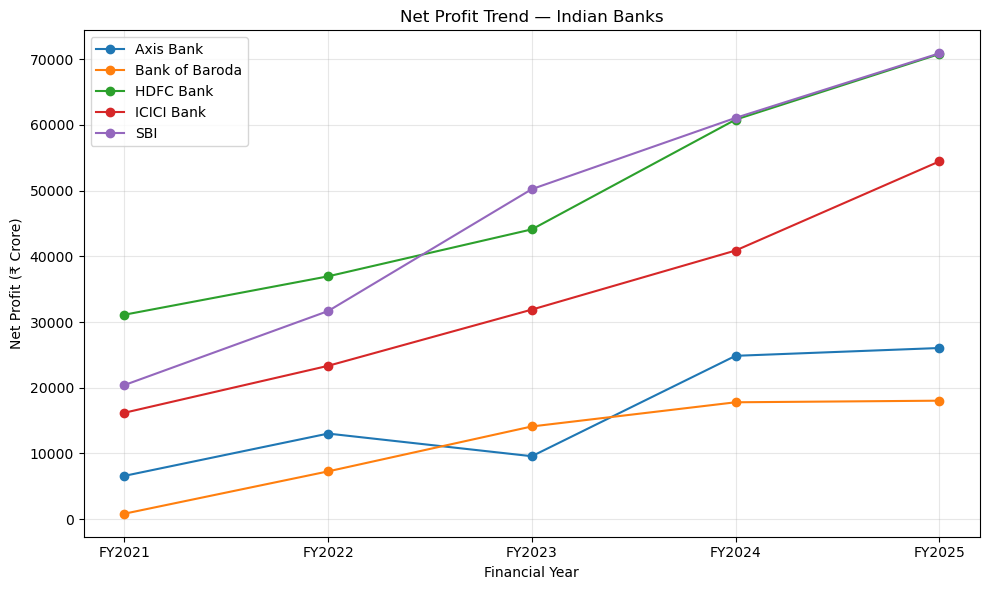

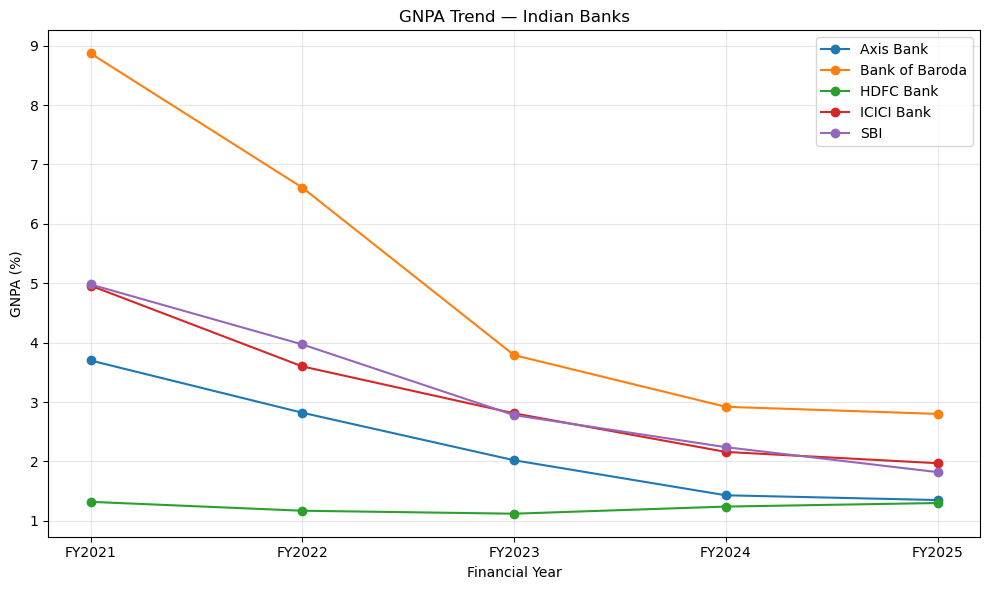

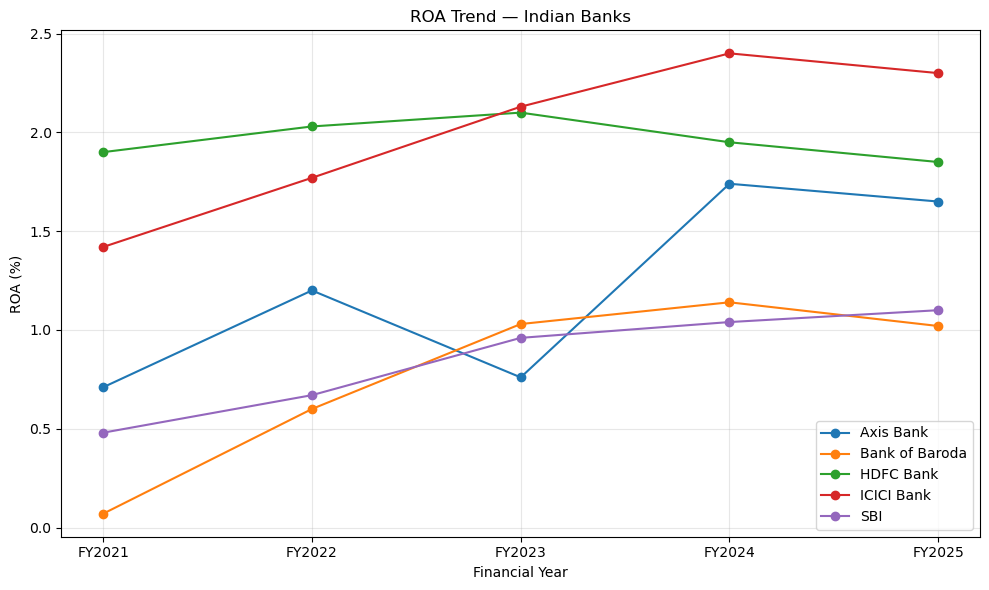

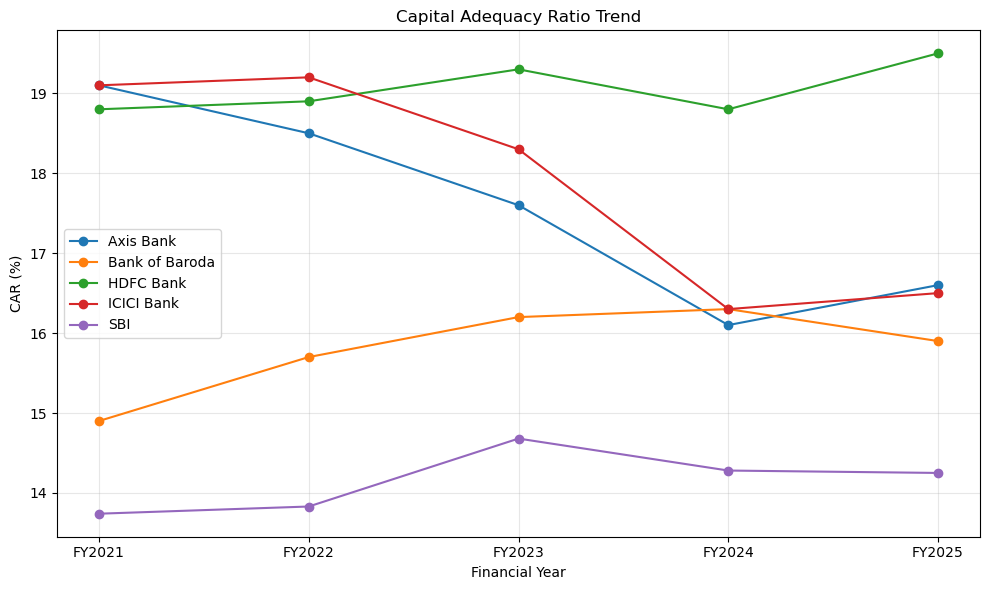

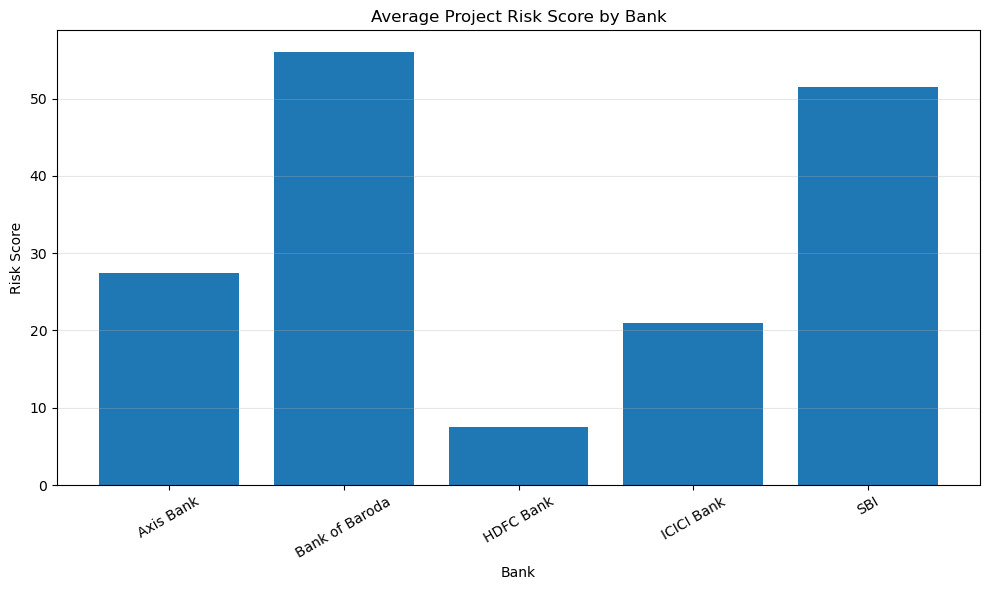

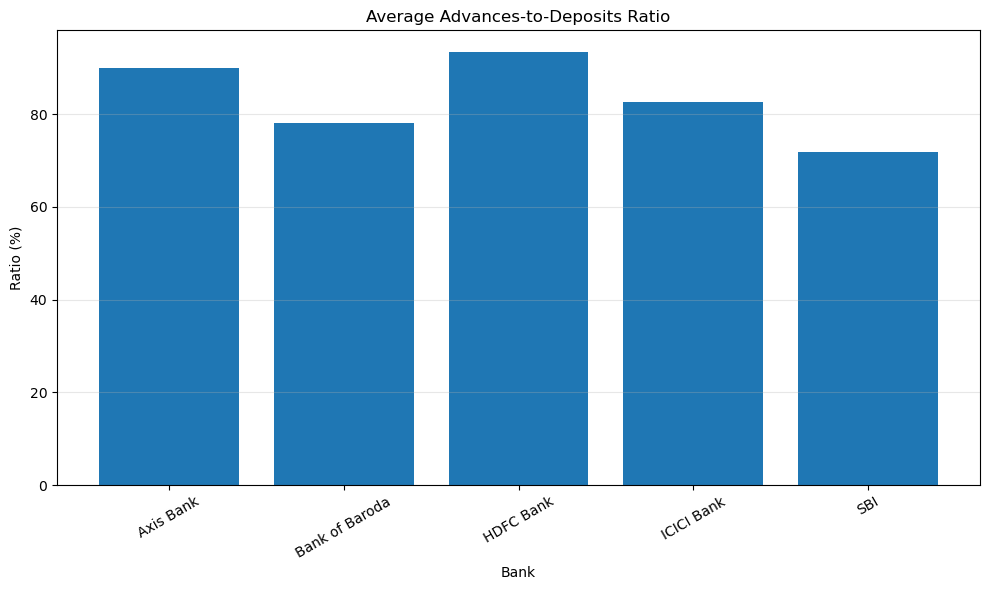

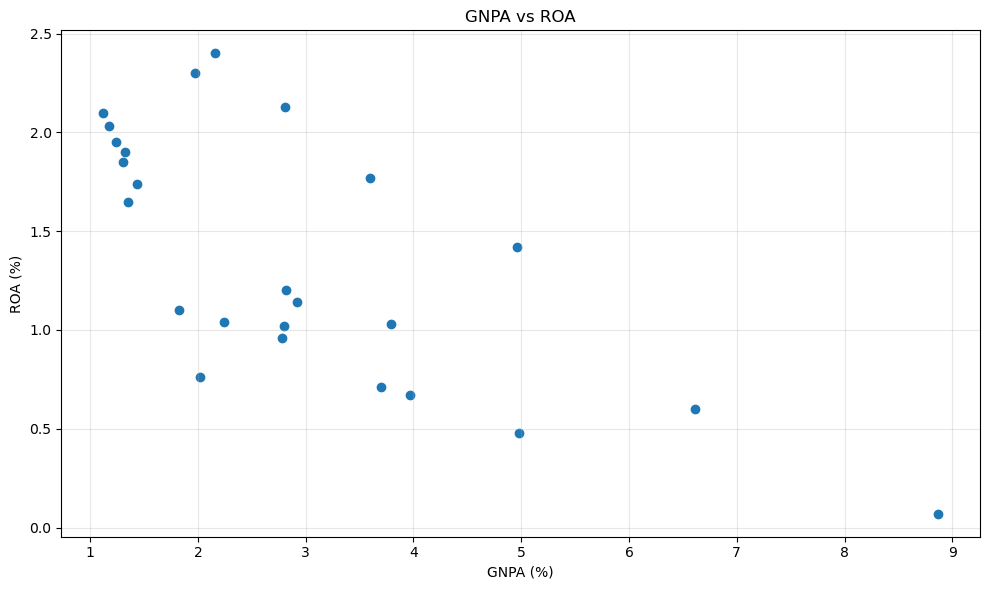


                 FINAL DASHBOARD TABLE
             Bank  Average_Net_Profit  Average_GNPA  Average_NNPA  \
0       Axis Bank             16020.8         0.023         0.006   
1  Bank of Baroda             11606.4         0.050         0.014   
2       HDFC Bank             48757.8         0.012         0.003   
3      ICICI Bank             33353.0         0.031         0.006   
4             SBI             46859.2         0.032         0.008   

   Average_ROA  Average_ROE  Average_CAR  Average_NIM  \
0        0.012        0.119        0.176        0.038   
1        0.008        0.114        0.158        0.031   
2        0.020        0.161        0.191        0.039   
3        0.020        0.163        0.179        0.042   
4        0.008        0.167        0.142        0.032   

   Average_Advances_Deposits_Ratio  Average_Risk_Score  
0                           89.912              27.377  
1                           78.126              56.019  
2                           93.

In [31]:
# ============================================================
# STEP 23 — FINAL BANKING RISK DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Prepare the data
# ============================================================

df = df.sort_values(
    ["Bank", "Year"]
).copy()


# ============================================================
# 2. Make sure important columns are numeric
# ============================================================

numeric_columns = [
    "Deposits",
    "Advances",
    "Total_Assets",
    "Net_Profit",
    "ROA",
    "ROE",
    "GNPA",
    "NNPA",
    "CAR",
    "NIM"
]

for col in numeric_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# 3. Create Advances-to-Deposits Ratio if necessary
# ============================================================

if "Advances_Deposits_Ratio" not in df.columns:

    df["Advances_Deposits_Ratio"] = (
        df["Advances"]
        /
        df["Deposits"]
    ) * 100


# ============================================================
# 4. Create Risk Score if necessary
# ============================================================

if "Risk_Score" not in df.columns:

    # GNPA risk
    df["GNPA_Risk"] = (
        (
            df["GNPA"] - df["GNPA"].min()
        )
        /
        (
            df["GNPA"].max() - df["GNPA"].min()
        )
    ) * 100


    # NNPA risk
    df["NNPA_Risk"] = (
        (
            df["NNPA"] - df["NNPA"].min()
        )
        /
        (
            df["NNPA"].max() - df["NNPA"].min()
        )
    ) * 100


    # ROA risk
    roa_normalized = (
        (
            df["ROA"] - df["ROA"].min()
        )
        /
        (
            df["ROA"].max() - df["ROA"].min()
        )
    ) * 100

    df["ROA_Risk"] = 100 - roa_normalized


    # CAR risk
    car_normalized = (
        (
            df["CAR"] - df["CAR"].min()
        )
        /
        (
            df["CAR"].max() - df["CAR"].min()
        )
    ) * 100

    df["CAR_Risk"] = 100 - car_normalized


    # Equal-weighted risk score
    df["Risk_Score"] = (
        df["GNPA_Risk"] * 0.25
        +
        df["NNPA_Risk"] * 0.25
        +
        df["ROA_Risk"] * 0.25
        +
        df["CAR_Risk"] * 0.25
    )


# ============================================================
# 5. Create bank-level summary
# ============================================================

bank_summary = df.groupby("Bank").agg(
    Average_Net_Profit=("Net_Profit", "mean"),
    Average_GNPA=("GNPA", "mean"),
    Average_NNPA=("NNPA", "mean"),
    Average_ROA=("ROA", "mean"),
    Average_ROE=("ROE", "mean"),
    Average_CAR=("CAR", "mean"),
    Average_NIM=("NIM", "mean"),
    Average_Advances_Deposits_Ratio=(
        "Advances_Deposits_Ratio",
        "mean"
    ),
    Average_Risk_Score=(
        "Risk_Score",
        "mean"
    )
).reset_index()


# ============================================================
# 6. Print dashboard summary
# ============================================================

print("\n============================================================")
print("             INDIAN BANKING RISK DASHBOARD")
print("============================================================")

print("\nBANK-LEVEL SUMMARY")
print("------------------------------------------------------------")

print(
    bank_summary.round(3)
)


# ============================================================
# 7. FY2025 snapshot
# ============================================================

fy2025 = df[
    df["Year"] == "FY2025"
].copy()


print("\nFY2025 SNAPSHOT")
print("------------------------------------------------------------")

print(
    fy2025[
        [
            "Bank",
            "Net_Profit",
            "GNPA",
            "NNPA",
            "ROA",
            "ROE",
            "CAR",
            "NIM",
            "Risk_Score"
        ]
    ].round(3)
)


# ============================================================
# 8. CHART 1 — Net Profit Trend
# ============================================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[
        df["Bank"] == bank
    ]

    plt.plot(
        bank_data["Year"],
        bank_data["Net_Profit"],
        marker="o",
        label=bank
    )

plt.title(
    "Net Profit Trend — Indian Banks"
)

plt.xlabel(
    "Financial Year"
)

plt.ylabel(
    "Net Profit (₹ Crore)"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 9. CHART 2 — GNPA Trend
# ============================================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[
        df["Bank"] == bank
    ]

    plt.plot(
        bank_data["Year"],
        bank_data["GNPA"] * 100,
        marker="o",
        label=bank
    )

plt.title(
    "GNPA Trend — Indian Banks"
)

plt.xlabel(
    "Financial Year"
)

plt.ylabel(
    "GNPA (%)"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 10. CHART 3 — ROA Trend
# ============================================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[
        df["Bank"] == bank
    ]

    plt.plot(
        bank_data["Year"],
        bank_data["ROA"] * 100,
        marker="o",
        label=bank
    )

plt.title(
    "ROA Trend — Indian Banks"
)

plt.xlabel(
    "Financial Year"
)

plt.ylabel(
    "ROA (%)"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. CHART 4 — CAR Trend
# ============================================================

plt.figure(figsize=(10, 6))

for bank in df["Bank"].unique():

    bank_data = df[
        df["Bank"] == bank
    ]

    plt.plot(
        bank_data["Year"],
        bank_data["CAR"] * 100,
        marker="o",
        label=bank
    )

plt.title(
    "Capital Adequacy Ratio Trend"
)

plt.xlabel(
    "Financial Year"
)

plt.ylabel(
    "CAR (%)"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. CHART 5 — Average Risk Score
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    bank_summary["Bank"],
    bank_summary["Average_Risk_Score"]
)

plt.title(
    "Average Project Risk Score by Bank"
)

plt.xlabel(
    "Bank"
)

plt.ylabel(
    "Risk Score"
)

plt.xticks(
    rotation=30
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. CHART 6 — Advances-to-Deposits Ratio
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    bank_summary["Bank"],
    bank_summary[
        "Average_Advances_Deposits_Ratio"
    ]
)

plt.title(
    "Average Advances-to-Deposits Ratio"
)

plt.xlabel(
    "Bank"
)

plt.ylabel(
    "Ratio (%)"
)

plt.xticks(
    rotation=30
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. CHART 7 — GNPA vs ROA
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    df["GNPA"] * 100,
    df["ROA"] * 100
)

plt.title(
    "GNPA vs ROA"
)

plt.xlabel(
    "GNPA (%)"
)

plt.ylabel(
    "ROA (%)"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 15. Final dashboard table
# ============================================================

dashboard_table = bank_summary[
    [
        "Bank",
        "Average_Net_Profit",
        "Average_GNPA",
        "Average_NNPA",
        "Average_ROA",
        "Average_ROE",
        "Average_CAR",
        "Average_NIM",
        "Average_Advances_Deposits_Ratio",
        "Average_Risk_Score"
    ]
].copy()


print("\n============================================================")
print("                 FINAL DASHBOARD TABLE")
print("============================================================")

print(
    dashboard_table.round(3)
)


print("\nStep 23 completed successfully!")

In [32]:
# ============================================================
# STEP 24 — BUSINESS FINDINGS & RISK INSIGHTS
# ============================================================

import pandas as pd
import numpy as np


# ============================================================
# 1. Prepare the data
# ============================================================

df = df.sort_values(
    ["Bank", "Year"]
).copy()


# ============================================================
# 2. Make sure important columns are numeric
# ============================================================

numeric_columns = [
    "Deposits",
    "Advances",
    "Total_Assets",
    "Net_Profit",
    "ROA",
    "ROE",
    "GNPA",
    "NNPA",
    "CAR",
    "NIM"
]

for col in numeric_columns:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )


# ============================================================
# 3. Create required features if they do not exist
# ============================================================

if "Advances_Deposits_Ratio" not in df.columns:

    df["Advances_Deposits_Ratio"] = (
        df["Advances"]
        /
        df["Deposits"]
    ) * 100


if "Profit_to_Assets" not in df.columns:

    df["Profit_to_Assets"] = (
        df["Net_Profit"]
        /
        df["Total_Assets"]
    ) * 100


if "Risk_Score" not in df.columns:

    df["GNPA_Risk"] = (
        (
            df["GNPA"] - df["GNPA"].min()
        )
        /
        (
            df["GNPA"].max() - df["GNPA"].min()
        )
    ) * 100

    df["NNPA_Risk"] = (
        (
            df["NNPA"] - df["NNPA"].min()
        )
        /
        (
            df["NNPA"].max() - df["NNPA"].min()
        )
    ) * 100

    roa_normalized = (
        (
            df["ROA"] - df["ROA"].min()
        )
        /
        (
            df["ROA"].max() - df["ROA"].min()
        )
    ) * 100

    df["ROA_Risk"] = (
        100 - roa_normalized
    )

    car_normalized = (
        (
            df["CAR"] - df["CAR"].min()
        )
        /
        (
            df["CAR"].max() - df["CAR"].min()
        )
    ) * 100

    df["CAR_Risk"] = (
        100 - car_normalized
    )

    df["Risk_Score"] = (
        df["GNPA_Risk"] * 0.25
        +
        df["NNPA_Risk"] * 0.25
        +
        df["ROA_Risk"] * 0.25
        +
        df["CAR_Risk"] * 0.25
    )


# ============================================================
# 4. Create FY2021 and FY2025 datasets
# ============================================================

start = df[
    df["Year"] == "FY2021"
].copy()

end = df[
    df["Year"] == "FY2025"
].copy()


# ============================================================
# 5. Merge beginning and ending values
# ============================================================

period = start.merge(
    end,
    on="Bank",
    suffixes=("_Start", "_End")
)


# ============================================================
# 6. Calculate five-year changes
# ============================================================

period["Net_Profit_Growth_%"] = (
    (
        period["Net_Profit_End"]
        -
        period["Net_Profit_Start"]
    )
    /
    period["Net_Profit_Start"]
) * 100


period["Deposit_Growth_%"] = (
    (
        period["Deposits_End"]
        -
        period["Deposits_Start"]
    )
    /
    period["Deposits_Start"]
) * 100


period["Advance_Growth_%"] = (
    (
        period["Advances_End"]
        -
        period["Advances_Start"]
    )
    /
    period["Advances_Start"]
) * 100


period["GNPA_Change_pp"] = (
    period["GNPA_End"]
    -
    period["GNPA_Start"]
) * 100


period["NNPA_Change_pp"] = (
    period["NNPA_End"]
    -
    period["NNPA_Start"]
) * 100


period["ROA_Change_pp"] = (
    period["ROA_End"]
    -
    period["ROA_Start"]
) * 100


period["CAR_Change_pp"] = (
    period["CAR_End"]
    -
    period["CAR_Start"]
) * 100


# ============================================================
# 7. Display five-year financial changes
# ============================================================

print("\n============================================================")
print("              FIVE-YEAR FINANCIAL ANALYSIS")
print("============================================================")

print(
    period[
        [
            "Bank",
            "Net_Profit_Growth_%",
            "Deposit_Growth_%",
            "Advance_Growth_%",
            "GNPA_Change_pp",
            "NNPA_Change_pp",
            "ROA_Change_pp",
            "CAR_Change_pp"
        ]
    ].round(3)
)


# ============================================================
# 8. Bank-level average indicators
# ============================================================

bank_summary = df.groupby("Bank").agg(
    Average_Net_Profit=("Net_Profit", "mean"),
    Average_GNPA=("GNPA", "mean"),
    Average_NNPA=("NNPA", "mean"),
    Average_ROA=("ROA", "mean"),
    Average_ROE=("ROE", "mean"),
    Average_CAR=("CAR", "mean"),
    Average_NIM=("NIM", "mean"),
    Average_Advances_Deposits_Ratio=(
        "Advances_Deposits_Ratio",
        "mean"
    ),
    Average_Risk_Score=(
        "Risk_Score",
        "mean"
    )
).reset_index()


# ============================================================
# 9. Display bank summary
# ============================================================

print("\n============================================================")
print("                  BANK-LEVEL SUMMARY")
print("============================================================")

print(
    bank_summary.round(3)
)


# ============================================================
# 10. Overall dataset statistics
# ============================================================

print("\n============================================================")
print("                OVERALL PROJECT STATISTICS")
print("============================================================")

print(
    "Average GNPA:",
    round(df["GNPA"].mean() * 100, 3),
    "%"
)

print(
    "Average NNPA:",
    round(df["NNPA"].mean() * 100, 3),
    "%"
)

print(
    "Average ROA:",
    round(df["ROA"].mean() * 100, 3),
    "%"
)

print(
    "Average ROE:",
    round(df["ROE"].mean() * 100, 3),
    "%"
)

print(
    "Average CAR:",
    round(df["CAR"].mean() * 100, 3),
    "%"
)


# ============================================================
# 11. Correlation analysis
# ============================================================

gnpa_roa_corr = df[
    ["GNPA", "ROA"]
].corr().iloc[0, 1]


gnpa_profit_corr = df[
    ["GNPA", "Net_Profit"]
].corr().iloc[0, 1]


advances_profit_corr = df[
    ["Advances", "Net_Profit"]
].corr().iloc[0, 1]


print("\n============================================================")
print("                  CORRELATION FINDINGS")
print("============================================================")

print(
    "GNPA vs ROA:",
    round(gnpa_roa_corr, 4)
)

print(
    "GNPA vs Net Profit:",
    round(gnpa_profit_corr, 4)
)

print(
    "Advances vs Net Profit:",
    round(advances_profit_corr, 4)
)


# ============================================================
# 12. Risk score movement
# ============================================================

risk_start = start[
    ["Bank", "Risk_Score"]
].rename(
    columns={
        "Risk_Score": "Risk_Score_Start"
    }
)

risk_end = end[
    ["Bank", "Risk_Score"]
].rename(
    columns={
        "Risk_Score": "Risk_Score_End"
    }
)


risk_change = risk_start.merge(
    risk_end,
    on="Bank"
)


risk_change["Risk_Score_Change"] = (
    risk_change["Risk_Score_End"]
    -
    risk_change["Risk_Score_Start"]
)


print("\n============================================================")
print("                  RISK SCORE MOVEMENT")
print("============================================================")

print(
    risk_change.round(3)
)


# ============================================================
# 13. Future GNPA prediction summary
# ============================================================

if "Future_GNPA_Increase" in df.columns:

    prediction_summary = df[
        df["Next_Year_GNPA"].notna()
    ].groupby("Bank")[
        "Future_GNPA_Increase"
    ].mean()

    print("\n============================================================")
    print("             FUTURE GNPA INCREASE FREQUENCY")
    print("============================================================")

    print(
        prediction_summary.round(3)
    )

else:

    print(
        "\nFuture prediction results are not available "
        "in the current DataFrame."
    )


# ============================================================
# 14. Identify largest five-year profit growth
# ============================================================

largest_profit_growth = period.loc[
    period["Net_Profit_Growth_%"].idxmax()
]

print("\n============================================================")
print("             PROFIT GROWTH OBSERVATION")
print("============================================================")

print(
    "Bank with the largest calculated FY2021-FY2025 "
    "profit growth:",
    largest_profit_growth["Bank"]
)

print(
    "Calculated growth:",
    round(
        largest_profit_growth[
            "Net_Profit_Growth_%"
        ],
        2
    ),
    "%"
)


# ============================================================
# 15. Identify largest GNPA reduction
# ============================================================

largest_gnpa_reduction = period.loc[
    period["GNPA_Change_pp"].idxmin()
]

print("\n============================================================")
print("                GNPA CHANGE OBSERVATION")
print("============================================================")

print(
    "Bank with the largest calculated GNPA reduction:",
    largest_gnpa_reduction["Bank"]
)

print(
    "Change:",
    round(
        largest_gnpa_reduction[
            "GNPA_Change_pp"
        ],
        3
    ),
    "percentage points"
)


# ============================================================
# 16. Identify largest GNPA increase
# ============================================================

largest_gnpa_increase = period.loc[
    period["GNPA_Change_pp"].idxmax()
]

print(
    "\nBank with the largest calculated GNPA increase:",
    largest_gnpa_increase["Bank"]
)

print(
    "Change:",
    round(
        largest_gnpa_increase[
            "GNPA_Change_pp"
        ],
        3
    ),
    "percentage points"
)


# ============================================================
# 17. Important interpretation rules
# ============================================================

print("\n============================================================")
print("                 INTERPRETATION RULES")
print("============================================================")

print(
    "1. A lower GNPA generally indicates lower "
    "reported gross non-performing assets."
)

print(
    "2. A lower NNPA generally indicates lower "
    "net non-performing assets."
)

print(
    "3. Higher ROA indicates stronger profitability "
    "relative to assets."
)

print(
    "4. Higher CAR indicates a larger capital buffer "
    "relative to risk-weighted exposure, all else equal."
)

print(
    "5. Risk Score is a project-specific relative score, "
    "not an official regulatory or credit rating."
)

print(
    "6. Correlation does not establish causation."
)

print(
    "7. Machine-learning results are exploratory because "
    "the dataset is very small."
)


# ============================================================
# 18. Project limitations
# ============================================================

print("\n============================================================")
print("                    PROJECT LIMITATIONS")
print("============================================================")

limitations = [
    "Only 5 banks are included.",
    "Only FY2021-FY2025 observations are included.",
    "The dataset contains only 25 bank-year observations.",
    "The risk score is a custom analytical score.",
    "Regression and ML results are exploratory.",
    "The dataset does not include all dimensions of banking risk.",
    "The project does not represent an official bank rating.",
    "HDFC Bank's FY2024/FY2025 figures require merger-related context."
]

for number, limitation in enumerate(
    limitations,
    start=1
):
    print(
        f"{number}. {limitation}"
    )


print("\nStep 24 completed successfully!")


              FIVE-YEAR FINANCIAL ANALYSIS
             Bank  Net_Profit_Growth_%  Deposit_Growth_%  Advance_Growth_%  \
0       Axis Bank              295.416            65.546            73.352   
1  Bank of Baroda             2075.151            54.777            75.171   
2       HDFC Bank              127.503           102.987           148.933   
3      ICICI Bank              236.250            72.687            82.629   
4             SBI              247.384            46.204            69.966   

   GNPA_Change_pp  NNPA_Change_pp  ROA_Change_pp  CAR_Change_pp  
0           -2.35           -0.71           0.94          -2.50  
1           -6.07           -2.49           0.95           1.00  
2           -0.02           -0.03          -0.05           0.70  
3           -2.99           -0.75           0.88          -2.60  
4           -3.16           -1.03           0.62           0.51  

                  BANK-LEVEL SUMMARY
             Bank  Average_Net_Profit  Average_GNPA  

In [1]:
import pandas as pd

# Load the original dataset
df = pd.read_excel("Project_1_Banking_Data.xlsx")

# Rename columns if necessary
df = df.rename(columns={
    "Provision Coverage Ratio": "Provision_Coverage_Ratio",
    "Cost/Income Ratio": "Cost_Income_Ratio"
})

# Convert financial columns to numeric
financial_columns = [
    "Deposits",
    "Advances",
    "Total_Assets",
    "Net_Profit",
    "ROA",
    "ROE",
    "GNPA",
    "NNPA",
    "CAR",
    "NIM",
    "Provision_Coverage_Ratio",
    "Cost_Income_Ratio"
]

for col in financial_columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", ""),
        errors="coerce"
    )

# Sort the data
df = df.sort_values(["Bank", "Year"]).reset_index(drop=True)

# Financial ratios
df["Advances_Deposits_Ratio"] = (
    df["Advances"] / df["Deposits"]
) * 100

df["Profit_to_Assets"] = (
    df["Net_Profit"] / df["Total_Assets"]
) * 100

# Growth calculations
df["Profit_Growth"] = (
    df.groupby("Bank")["Net_Profit"].pct_change() * 100
)

df["Deposit_Growth"] = (
    df.groupby("Bank")["Deposits"].pct_change() * 100
)

df["Advance_Growth"] = (
    df.groupby("Bank")["Advances"].pct_change() * 100
)

df["Asset_Growth"] = (
    df.groupby("Bank")["Total_Assets"].pct_change() * 100
)

# GNPA and NNPA changes
df["GNPA_Change"] = (
    df.groupby("Bank")["GNPA"].diff()
)

df["NNPA_Change"] = (
    df.groupby("Bank")["NNPA"].diff()
)

# Risk flags
df["GNPA_Risk_Flag"] = (
    df["GNPA"] > 0.03
).astype(int)

df["NNPA_Risk_Flag"] = (
    df["NNPA"] > 0.01
).astype(int)

# GNPA trend
df["GNPA_Trend"] = df.groupby("Bank")["GNPA"].diff()

df["GNPA_Trend"] = df["GNPA_Trend"].apply(
    lambda x: "Increasing" if x > 0
    else ("Decreasing" if x < 0 else "No Change")
)

# Combined risk flag
df["Combined_Risk_Flag"] = (
    (df["GNPA_Risk_Flag"] == 1) |
    (df["NNPA_Risk_Flag"] == 1)
).astype(int)

# Create Risk Score if it does not already exist
if "Risk_Score" not in df.columns:

    df["GNPA_Risk"] = (
        (df["GNPA"] - df["GNPA"].min()) /
        (df["GNPA"].max() - df["GNPA"].min())
    ) * 100

    df["NNPA_Risk"] = (
        (df["NNPA"] - df["NNPA"].min()) /
        (df["NNPA"].max() - df["NNPA"].min())
    ) * 100

    roa_normalized = (
        (df["ROA"] - df["ROA"].min()) /
        (df["ROA"].max() - df["ROA"].min())
    ) * 100

    df["ROA_Risk"] = 100 - roa_normalized

    car_normalized = (
        (df["CAR"] - df["CAR"].min()) /
        (df["CAR"].max() - df["CAR"].min())
    ) * 100

    df["CAR_Risk"] = 100 - car_normalized

    df["Risk_Score"] = (
        df["GNPA_Risk"] * 0.25 +
        df["NNPA_Risk"] * 0.25 +
        df["ROA_Risk"] * 0.25 +
        df["CAR_Risk"] * 0.25
    )

# Future GNPA
df["Next_Year_GNPA"] = (
    df.groupby("Bank")["GNPA"].shift(-1)
)

df["Future_GNPA_Increase"] = (
    df["Next_Year_GNPA"] > df["GNPA"]
).astype(int)

# Save final Power BI dataset
df.to_csv(
    "final_banking_dataset.csv",
    index=False
)

# Check final dataset
print("Final Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
print(df.head())

print("\nFinal dataset saved as:")
print("final_banking_dataset.csv")

Final Dataset Shape: (25, 33)

Columns:
['Bank', 'Year', 'Deposits', 'Advances', 'Total_Assets', 'Net_Profit', 'ROA', 'ROE', 'GNPA', 'NNPA', 'CAR', 'NIM', 'Provision_Coverage_Ratio', 'Cost_Income_Ratio', 'Advances_Deposits_Ratio', 'Profit_to_Assets', 'Profit_Growth', 'Deposit_Growth', 'Advance_Growth', 'Asset_Growth', 'GNPA_Change', 'NNPA_Change', 'GNPA_Risk_Flag', 'NNPA_Risk_Flag', 'GNPA_Trend', 'Combined_Risk_Flag', 'GNPA_Risk', 'NNPA_Risk', 'ROA_Risk', 'CAR_Risk', 'Risk_Score', 'Next_Year_GNPA', 'Future_GNPA_Increase']

First 5 Rows:
        Bank    Year  Deposits  Advances  Total_Assets  Net_Profit     ROA  \
0  Axis Bank  FY2021    707306    623720        996118        6588  0.0071   
1  Axis Bank  FY2022    821721    707696       1175178       13025  0.0120   
2  Axis Bank  FY2023    946945    845303       1344418        9580  0.0076   
3  Axis Bank  FY2024   1067100    999330       1518240       24861  0.0174   
4  Axis Bank  FY2025   1170920   1081230       1656960       26050 